# Практическая работа № 1. Открытые API, парсинг HTML (BeautifulSoup, XPath) и регулярные выражения

**Дисциплина:** «Программные средства сбора, консолидации и аналитики данных»  
**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Программа:** «Бизнес-аналитика и большие данные»  
**Тема:** 1. Программные средства сбора данных  
**Формат:** интерактивный ноутбук Google Colab · **максимум 10 баллов** · срок сдачи — в Moodle (EnvLab)

## Цель работы

Научиться самостоятельно добывать рыночные данные там, где нет готового датасета: забирать их из открытых API, извлекать из HTML-страниц, приводить «грязный» текст к числам и датам и превращать результат в управленческие выводы.

## Задачи

1. Спроектировать вежливый сбор данных через REST API: параметры, пагинация, заголовки, паузы, повторные попытки, обработка ошибок.
2. Извлечь данные из статических HTML-страниц двумя независимыми способами — CSS-селекторами BeautifulSoup и выражениями XPath — и сверить результаты.
3. Нормализовать «грязные» значения регулярными выражениями (числа, цены, остатки, даты; зарплаты и навыки — если они присутствуют в данных вашего варианта).
4. Подготовить таблицы `pandas` для API и HTML-данных, проверить качество, провести разведочный анализ и построить **не менее четырёх графиков** по варианту.
5. Сформулировать выводы и рекомендации для лица, принимающего решение, с опорой на посчитанные метрики.

## Стек

| Слой | Инструменты |
|---|---|
| Сбор | `requests` (+ `urllib3.Retry`), открытые REST API, кэш ответов на диске |
| Разбор HTML | `BeautifulSoup4` (CSS-селекторы), `lxml` (XPath) |
| Очистка | `re` — регулярные выражения |
| Анализ и графики | `pandas`, `numpy`, `matplotlib`, `seaborn` |
| Среда | Google Colab (работает и в локальном Jupyter) |

## Что сдаётся

Выполненный ноутбук **со всеми выводами ячеек**, загруженный в личный публичный репозиторий GitHub; в LMS сдаётся **ссылка на репозиторий**. Файлы и архивы не принимаются. Ключи, токены и пароли в ноутбуке недопустимы — за это снимаются баллы (см. раздел «Штрафы»).

## 🔧 Выполнение работы: вариант 2

**Вариант 2 · E-commerce:** «Ценовое позиционирование в нише деловой литературы».
**API:** «Работа в России» (`opendata.trudvsem.ru`), запрос «аналитик маркетплейсов», 4 стр. × 100.
**Сайт:** `books.toscrape.com`, категория Business (`business_35`), до 3 страниц.
**Метрики варианта:** распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат.
**Дата сбора:** 17.10.2026.

### Как найти изменения в этой копии

| Метка | Что означает |
|---|---|
| `✅ ВЫПОЛНЕНО TODO x.y` (в коде) | код, написанный вместо заглушки `todo(...)` |
| `✅ ИЗМЕНЕНО` / `✅ ИСПРАВЛЕНО` (в коде) | правка исходного шаблона и её причина |
| `✅ ДОБАВЛЕНО` (в коде) | код или ячейка сверх обязательного минимума |
| 💬 **Комментарий к выполнению** | что сделано на шаге и что показал результат |

### Сводка изменений

1. **Шаг 1.** `VARIANT = 2`; добавлен `pyarrow` (нужен для задания D); в `polite_get()` исправлена кодировка HTML-ответов.
2. **Шаг 2.** `fetch_api()` с пагинацией и условием остановки, `normalize_api()` без персональных данных, журнал запросов.
3. **Шаг 3.** `parse_with_bs4()`, `parse_with_xpath()`, `collect_site()`, сверка BS4 и XPath по всем полям. **Новая ячейка 3.4:** страницы товаров (точный остаток через XPath `following-sibling`).
4. **Шаг 4.** Шесть RegEx-функций, 17 собственных тестов, `clean_web()` и `clean_api()`, отчёт о качестве и доле распознанных значений.
5. **Шаг 5.** Четыре графика по метрикам варианта.
6. **Шаг 6.** Ячейка 6.1 со специфическими показателями и заполненные выводы.
7. **Самопроверка.** Обоснован объём выборки (оба источника объективно меньше ориентира).
8. **Задание со звёздочкой.** Выполнены направления **E** (устойчивость парсера) и **D** (мониторинг снимков).


## Как работать с этим ноутбуком

1. **Файл → Сохранить копию на Диске.** Работайте только в своей копии.
2. В ячейке «Шаг 1» задайте **номер варианта** (выдаёт преподаватель), свой контактный e-mail и паузу между запросами. Параметры варианта подставятся автоматически.
3. Выполняйте ячейки **строго сверху вниз**. Перед каждым блоком кода есть пояснение «Зачем мы это делаем», после — «Как читать полученный вывод».
4. Места, которые нужно дописать, помечены `TODO`. Пока шаг не выполнен, ячейка честно падает с `NotImplementedError` — это нормально.
5. Перед сдачей запустите ячейку **самопроверки**. Она различает **✅ выполнено**, **❌ требует исправления**, **➖ не применяется** и **⚠ требует обоснования**. Число применимых проверок зависит от варианта; все применимые требования должны быть выполнены.
6. Если источник объективно предоставляет меньше 50 API-записей или 40 HTML-объектов, заполните пояснение непосредственно в ячейке самопроверки и в выводах. Самопроверка пометит этот пункт как требующий проверки преподавателем. Дублировать данные и подменять исходный вариант нельзя.
7. Номер варианта, показанный при первом открытии ноутбука, — **пример настройки**, а не назначение студенту. Выберите выданный преподавателем вариант.

### Три правила вежливого сбора данных

* **Пауза между запросами.** `REQUEST_PAUSE = 0.5` секунды — исходный учебный ориентир, не универсальное разрешение на такую частоту. Соблюдайте ограничения API, `Retry-After`, правила сайта и при необходимости увеличивайте паузу.
* **Кэш включён по умолчанию.** Повторный запуск ячейки берёт ответ с диска, а не из сети: это и быстрее, и вежливее. Чтобы получить свежие данные, выключите `USE_CACHE` или очистите папку кэша.
* **Никаких ключей в коде.** Токены читаются функцией `get_secret()` из Colab Secrets (значок ключа слева) или переменных окружения.

### Если источник недоступен

Интернет в Colab иногда блокирует отдельные домены, а сайты меняют вёрстку. В ноутбуке предусмотрены аварийные режимы (синтетические данные и офлайн-снимок разметки): пайплайн доработает до конца, но в выводе появится предупреждение. **Учебные или синтетические данные нельзя представлять как фактические рыночные результаты**; пометьте их источник и ограничения и повторите сбор, когда исходный ресурс станет доступен.

## Мини-теория 1. REST API: как устроен этичный сбор

**API** — это контракт: вы отправляете HTTP-запрос по определённому адресу и получаете структурированный ответ (почти всегда JSON). В отличие от парсинга HTML, здесь данные уже разобраны по полям, а правила использования описаны явно.

### Анатомия запроса

```
GET https://api.github.com/search/repositories ? q=web+scraping & sort=stars & per_page=50 & page=2
    └──────── эндпоинт ────────────────────────┘ └──────────── параметры запроса ───────────────┘
Заголовки: User-Agent: MGPU-BI-PW1/1.0 (contact: student@mgpu.ru)
           Authorization: Bearer <токен>        ← если сервис требует авторизацию
```

* **Эндпоинт** — «ручка» сервиса: `/vacancies`, `/works`, `/search/repositories`.
* **Параметры** уточняют выборку: поисковая строка, фильтры, сортировка, размер страницы.
* **Заголовки** описывают клиента. `User-Agent` с контактом — правило хорошего тона: по нему администратор сервиса сможет с вами связаться, а не просто заблокировать.
* **Коды ответа** — первое, что нужно проверять:

| Код | Что значит | Что делать |
|---|---|---|
| 200 | всё хорошо | разбирать `r.json()` |
| 301 / 302 | адрес изменился | проверить итоговый `r.url` |
| 400 | неверные параметры | сверить имена и типы параметров с документацией |
| 401 / 403 | нет доступа или ключа | получить ключ, проверить заголовки; иногда сервис закрыл публичный доступ |
| 404 | объекта нет | проверить путь и идентификатор |
| 429 | превышен лимит | подождать `Retry-After`, увеличить паузу |
| 5xx | сбой на стороне сервиса | повторить с экспоненциальной задержкой |

### Пагинация

Сервисы отдают данные страницами. Три частых схемы:

| Схема | Параметры | Примеры |
|---|---|---|
| Номер страницы | `page`, `per_page` | GitHub, OpenAlex |
| Смещение и размер | `offset`, `limit` | «Работа в России» |
| Курсор | `cursor`, `next` | сервисы с большим объёмом |

Правило остановки: страница вернула меньше записей, чем `per_page`, — данные закончились. Бесконечный `while True` без такой проверки — классическая ошибка, которая либо зациклится, либо упрётся в лимит.

### Ограничение частоты (rate limiting)

Сервис считает ваши запросы и при превышении отвечает 429. Практика:

* пауза между запросами (`time.sleep`);
* повторные попытки с **экспоненциальной задержкой** — в работе это `urllib3.Retry(backoff_factor=1.5)`: 1,5 с → 3 с → 6 с;
* уважение заголовков `X-RateLimit-Remaining` и `Retry-After`;
* кэширование ответов, чтобы при отладке не ходить в сеть повторно.

### Ключи и секреты

Многие API требуют ключ. Хранить его в коде нельзя: ноутбук уедет в репозиторий вместе с ключом, и ключ придётся отзывать. В Colab есть **Secrets** (значок ключа на панели слева): значение хранится в аккаунте, а код получает его через `userdata.get("MY_KEY")`. В работе это обёрнуто в `get_secret()`.

### Что изменилось к 2026 году (важно для выбора источника)

* **hh.ru**: с апреля 2026 публичный метод `GET /vacancies` отвечает `403 Forbidden` на неавторизованные запросы; ключ выдают в основном работодателям и рекрутинговым сервисам через модерацию приложения. Старые учебные примеры с hh.ru больше не воспроизводятся. Российская открытая альтернатива — портал **«Работа в России»** (`opendata.trudvsem.ru`), данные Роструда, ключ не нужен.
* **OpenAlex**: с 13 февраля 2026 всем запросам нужен бесплатный `api_key`, параметр `mailto` и «polite pool» отменены. Действует бесплатный лимит около $1 в сутки; запросы `search` дороже, чем `filter`, а получение объекта по идентификатору бесплатно. Отсюда практический приём: `per-page=100` и фильтры вместо поиска.
* **GitHub**: без токена — 60 запросов в час на IP, с персональным токеном — 5000 в час; у поиска отдельный лимит (10 и 30 запросов в минуту соответственно).

Вывод для аналитика: **источник — это не константа**. Перед сбором проверяйте документацию и код ответа, а в отчёте фиксируйте дату сбора.

## Мини-теория 2. HTML, DOM и селекторы: BeautifulSoup против XPath

Когда API нет, данные забирают из HTML. Браузер превращает разметку в **DOM** — дерево элементов:

```
html
└── body
    └── article.product_pod                 ← карточка товара
        ├── h3 > a[title="Sharp Objects"]   ← название лежит в АТРИБУТЕ, а не в тексте
        ├── p.star-rating.Three             ← рейтинг закодирован КЛАССОМ
        └── div.product_price
            ├── p.price_color   → "£47.82"
            └── p.instock.availability → "In stock (22 available)"
```

Задача парсера — описать путь к нужному узлу так, чтобы он пережил мелкие изменения вёрстки.

### Два инструмента

| | BeautifulSoup + CSS | lxml + XPath |
|---|---|---|
| Синтаксис | `soup.select("article.product_pod p.price_color")` | `tree.xpath('//article[contains(@class,"product_pod")]//p[@class="price_color"]/text()')` |
| Читаемость | выше, привычно по вёрстке | ниже, но выражения мощнее |
| Атрибут | `el.get("title")` | `.../@title` |
| Текст | `el.get_text(" ", strip=True)` | `.../text()` |
| Поиск по тексту | `soup.find("th", string="UPC")` | `//th[text()="UPC"]` |
| Движение «вверх» и «вбок» | `el.parent`, `el.find_next_sibling()` | оси: `parent::`, `following-sibling::`, `ancestor::` |
| Условие по числу | средствами Python | `[position() <= 3]`, `[last()]` |
| Скорость | ниже (чистый Python поверх парсера) | выше (C-библиотека) |

**Когда что удобнее.** CSS-селекторы — для «плоских» повторяющихся карточек. XPath — когда нужно зацепиться за текст-подпись и взять соседнюю ячейку: классика — таблица характеристик товара:

```python
# «Найти ячейку th со словом UPC и взять следующий за ней td»
tree.xpath('//th[text()="UPC"]/following-sibling::td[1]/text()')
```

### Практические правила

1. **Цепляйтесь за смысл, а не за форму.** `div > div > div:nth-child(3)` сломается при первом же редизайне; `p.price_color` переживёт его.
2. **Проверяйте на нескольких страницах.** Первая страница часто не показательна: где-то нет скидки, где-то нет рейтинга.
3. **Отсутствие элемента — норма.** `select_one()` вернёт `None`; парсер должен записать `None` в поле, а не падать.
4. **Сверяйте два способа.** В этой работе один и тот же набор разбирается BS4 и XPath: расхождение — сигнал об ошибке в селекторе.
5. **Динамические сайты.** Если данные подгружаются JavaScript, в HTML их нет. Тогда ищут тот же запрос в панели «Сеть» браузера и обращаются к нему напрямую — это снова API.

## Мини-теория 3. Регулярные выражения для «грязных» данных

Из API и HTML приходят строки, а бизнес-метрики считаются по числам и датам. Регулярные выражения — самый короткий путь от `"от 60 000 до 90 000 руб."` к паре `(60000, 90000)`.

### Рабочий минимум синтаксиса

| Конструкция | Значение | Пример |
|---|---|---|
| `\d`, `\w`, `\s` | цифра, буква/цифра/подчёркивание, пробельный символ | `\d{4}` — год |
| `+`, `*`, `?`, `{n,m}` | повторения | `\d{1,3}` |
| `(?P<name>...)` | именованная группа | `(?P<min>\d+)` → `m.group("min")` |
| `(?:...)` | группировка без захвата | `(?:руб\.?|₽)` |
| `[...]`, `[^...]` | символьный класс и его отрицание | `[£$€₽]` |
| `\b` | граница слова | `\bBI\b` не совпадёт внутри `BigData` |
| `?` после квантификатора | ленивый режим | `<.+?>` |
| `re.I`, `re.S`, `re.X` | флаги: регистр, `.` включая перевод строки, «читаемый» режим | |

Функции: `re.search` — первое совпадение, `re.findall` — все, `re.sub` — замена, `re.compile` — скомпилировать один раз и переиспользовать.

### Шаблоны, которые понадобятся в работе

| Задача | Выражение | Тонкость |
|---|---|---|
| Цена | `(?P<num>\d{1,3}(?:[\s\u00a0]\d{3})*(?:[.,]\d{1,2})?)` | в `1 250,50 ₽` стоит **неразрывный** пробел `\u00a0`, а десятичный разделитель — запятая |
| Остаток | `\((?P<n>\d+)\s*available\)` | «Out of stock» — это ноль, а не пропуск |
| Зарплатная вилка | `(?:от\s*(?P<min>\d[\d\s]*))?\s*(?:до\s*(?P<max>\d[\d\s]*))?` | «по договорённости» → `(None, None)`; одиночное число — это и нижняя, и верхняя граница |
| Дата | `(?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4})` и `\d{4}-\d{2}-\d{2}` | в одном источнике встречаются оба формата |
| Технология в тексте | `(?<![\w])(python|sql|power bi)(?![\w])` | без границ `bi` найдётся в «combined» |

### Чего делать не нужно

* **Разбирать HTML регулярками.** Для разметки есть парсер дерева; регулярное выражение сломается на вложенности и незакрытых тегах. Регулярки применяются к уже извлечённому тексту.
* **Писать одно «универсальное» выражение на все случаи.** Проще и надёжнее несколько маленьких функций с тестами.
* **Верить, что очистка прошла успешно.** Всегда считайте долю распознанных значений: если цена распозналась в 62 % строк, дальше вы анализируете смещённую выборку.

В работе каждая функция очистки сопровождается набором тестов вида «вход → ожидаемый выход». Это дешёвая страховка: при изменении формата данных тест падает сразу, а не через три графика.

## Право и этика сбора данных

Аналитик отвечает не только за качество данных, но и за законность их получения.

* **`robots.txt` и пользовательское соглашение.** Перед сбором смотрим `https://сайт/robots.txt` и раздел об использовании данных. Запрет в `robots.txt` — не «рекомендация для поисковиков», а явно выраженная воля владельца ресурса.
* **Нагрузка.** Массовые запросы без пауз — это фактически мини-DDoS. Пауза, кэш и ограничение глубины пагинации обязательны.
* **Персональные данные.** Имена, контакты, резюме — персональные данные (152-ФЗ). В учебной работе они не собираются и не публикуются; в репозиторий выкладываются только агрегаты и обезличенные поля.
* **Авторские права и лицензии.** Тексты и изображения защищены авторским правом; открытые данные публикуются под лицензией, которую нужно указать в отчёте.
* **Прозрачность.** В `User-Agent` указывается назначение и контакт. Маскировка под браузер, обход капчи и ротация прокси в учебной работе не используются.

Поэтому в работе намеренно выбраны **учебные витрины** (`books.toscrape.com`, `quotes.toscrape.com`, `webscraper.io/test-sites`, `scrapethissite.com`), созданные специально для тренировки, и **открытые государственные и научные данные**. Навык переносится на коммерческие источники, а юридические риски — нет.

### Шаг 1. Окружение, параметры варианта и работа с ключами

**Зачем мы это делаем.** Прежде чем отправить первый запрос, нужно подготовить инфраструктуру сбора: клиент с повторными попытками, паузами и кэшем, единый `User-Agent` с контактом и безопасный способ получить ключ. Это тот код, который в реальном проекте пишется один раз и переиспользуется во всех сборах.

Обратите внимание на три детали:

* `Retry(backoff_factor=1.5, status_forcelist=(429, 500, 502, 503, 504))` — автоматические повторы с нарастающей паузой только для тех кодов, где повтор имеет смысл;
* `polite_get()` никогда не выбрасывает исключение: она возвращает пару «данные, метаинформация», и ошибка становится обычной веткой логики, а не аварией всего ноутбука;
* `get_secret()` ищет ключ в Colab Secrets, затем в переменных окружения и только потом спрашивает его с клавиатуры.

In [ ]:
#@title Шаг 1. Окружение, параметры варианта и безопасная работа с ключами { display-mode: "form" }
VARIANT = 2               #@param {type:"slider", min:1, max:30, step:1}
# ✅ ИЗМЕНЕНО: выбран назначенный вариант 2.
CONTACT_EMAIL = "bobylevavv287@mgpu.ru"  #@param {type:"string"}
USE_CACHE = True          #@param {type:"boolean"}
REQUEST_PAUSE = 0.5       #@param {type:"slider", min:0.1, max:3, step:0.1}

import importlib, io, json, math, os, random, re, subprocess, sys, textwrap, time, hashlib, warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from collections import Counter

def ensure(pkg, module=None):
    """Ставим пакет только если его нет: в Colab почти всё уже предустановлено."""
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("requests", "requests"), ("beautifulsoup4", "bs4"), ("lxml", "lxml"),
                 ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn"),
                 ("pyarrow", "pyarrow")]:   # ✅ ДОБАВЛЕНО: parquet-снимки (задание D)
    ensure(pkg, mod)

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from lxml import html as lxml_html, etree as lxml_etree
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

# --- вежливый HTTP-клиент: User-Agent с контактом, ретраи, экспоненциальная пауза --------
# Заголовки HTTP передаются в latin-1, поэтому User-Agent пишем только латиницей.
USER_AGENT = f"MGPU-BI-PW1/1.0 (educational project; contact: {CONTACT_EMAIL})"

def make_session(total=4, backoff=1.5):
    s = requests.Session()
    retry = Retry(total=total, backoff_factor=backoff,
                  status_forcelist=(408, 429, 500, 502, 503, 504),
                  allowed_methods=frozenset(["GET"]),
                  respect_retry_after_header=True)
    adapter = HTTPAdapter(max_retries=retry, pool_maxsize=8)
    s.mount("https://", adapter)
    s.mount("http://", adapter)
    s.headers.update({"User-Agent": USER_AGENT, "Accept-Encoding": "gzip, deflate"})
    return s

SESSION = make_session()
CACHE_DIR = Path("/content/pw1_cache" if Path("/content").exists() else "pw1_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
REQUEST_LOG = []

def polite_get(url, params=None, headers=None, expect="json", timeout=25,
               pause=None, use_cache=None):
    """Один GET-запрос: кэш → сеть → пауза. Возвращает (data, meta); исключения не выбрасываются.

    meta содержит статус, время ответа, признак кэша и остаток лимита, если сервер его сообщил.
    """
    pause = REQUEST_PAUSE if pause is None else pause
    use_cache = USE_CACHE if use_cache is None else use_cache
    key = hashlib.sha1(f"{url}|{json.dumps(params, sort_keys=True, ensure_ascii=False, default=str)}"
                       .encode("utf-8")).hexdigest()[:16]
    cached = CACHE_DIR / f"{key}.{'json' if expect == 'json' else 'txt'}"
    if use_cache and cached.exists():
        raw = cached.read_text(encoding="utf-8")
        meta = {"url": url, "status": 200, "from_cache": True, "error": None}
        REQUEST_LOG.append(meta)
        return (json.loads(raw) if expect == "json" else raw), meta

    meta = {"url": url, "status": None, "from_cache": False, "error": None}
    try:
        r = SESSION.get(url, params=params, headers=headers, timeout=timeout)
    except (requests.RequestException, UnicodeError) as e:   # сеть, таймаут, DNS, битый заголовок
        meta["error"] = f"{type(e).__name__}: {e}"
        REQUEST_LOG.append(meta)
        return None, meta

    meta.update(status=r.status_code, elapsed_s=round(r.elapsed.total_seconds(), 2),
                limit_remaining=r.headers.get("X-RateLimit-Remaining"))
    if r.status_code == 429:
        meta["error"] = "429 Too Many Requests: превышен лимит, увеличьте паузу"
    elif r.status_code != 200:
        meta["error"] = f"HTTP {r.status_code}: {r.text[:180]}"
    REQUEST_LOG.append(meta)
    if meta["error"]:
        return None, meta

    time.sleep(pause)                                  # вежливость: не «долбим» сервер
    if expect == "json":
        try:
            data = r.json()
        except ValueError as e:
            meta["error"] = f"ответ не JSON: {e}"
            return None, meta
        cached.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    else:
        # ✅ ИСПРАВЛЕНО: books.toscrape не указывает charset в заголовке, и requests по стандарту
        # HTTP декодирует страницу как ISO-8859-1 → «Â£51.77», «Entrepreneurâs». Определяем
        # кодировку по содержимому (на практике — UTF-8).
        if (r.encoding or "").lower() in ("", "iso-8859-1"):
            r.encoding = r.apparent_encoding or "utf-8"
        data = r.text
        cached.write_text(data, encoding="utf-8")
    return data, meta

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def get_secret(name, hint=""):
    """Ключи берём из Colab Secrets → переменных окружения → ввода с клавиатуры.
    Хардкодить ключ в ячейке нельзя: ноутбук уедет в Git вместе с ним."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    if os.environ.get(name):
        return os.environ[name]
    try:
        import getpass
        return getpass.getpass(f"{name} {hint}: ").strip() or None
    except Exception:
        return None

import bs4
print(f"Python {sys.version.split()[0]} | requests {requests.__version__} | bs4 {bs4.__version__} | "
      f"lxml {lxml_etree.__version__} | pandas {pd.__version__} | seaborn {sns.__version__}")
print(f"Вариант: {VARIANT} | кэш: {CACHE_DIR} | пауза между запросами: {REQUEST_PAUSE} с")

Python 3.12.14 | requests 2.34.2 | bs4 4.15.0 | lxml 6.1.3 | pandas 3.0.6 | seaborn 0.13.2
Вариант: 2 | кэш: pw1_cache | пауза между запросами: 0.5 с


**Как читать вывод.** В строке версий проверьте, что все библиотеки импортировались: в Colab они предустановлены, установка запускается только при отсутствии. Путь кэша пригодится, если понадобится принудительно обновить данные — достаточно удалить папку. Для публичных ресурсов ориентируйтесь на опубликованные ограничения и ответ сервера; при необходимости увеличьте паузу и обрабатывайте `429`/`Retry-After`.

In [ ]:
#@title Шаг 1.1. Параметры моего варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"area": "HR-аналитика",
"task": "Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят",
"api": "trudvsem",
"api_params": {
"text": "инженер машинного обучения",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога"
},
{
"id": 2,
"area": "E-commerce",
"task": "Ценовое позиционирование в нише деловой литературы",
"api": "trudvsem",
"api_params": {
"text": "аналитик маркетплейсов",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат"
},
{
"id": 3,
"area": "Финтех",
"task": "Валютный риск закупок: динамика USD и EUR за квартал",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 90
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли"
},
{
"id": 4,
"area": "Мониторинг конкурентов",
"task": "Сравнение ассортимента двух товарных категорий",
"api": "github",
"api_params": {
"q": "price monitoring",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "fiction_10",
"pages": 4
},
"metrics": "Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки»"
},
{
"id": 5,
"area": "Наука и инновации",
"task": "Научная активность в сфере FinTech: динамика публикаций",
"api": "openalex",
"api_params": {
"search": "fintech",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "quotes",
"site_params": {
"tag": "inspirational",
"pages": 4
},
"metrics": "Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов"
},
{
"id": 6,
"area": "Логистика",
"task": "Погодные риски на складских хабах: планирование окон отгрузки",
"api": "openmeteo",
"api_params": {
"cities": [
"Москва",
"Екатеринбург",
"Новосибирск"
],
"days": 14
},
"site": "books",
"site_params": {
"category": "history_32",
"pages": 2
},
"metrics": "Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога"
},
{
"id": 7,
"area": "HR-аналитика",
"task": "Спрос на дата-инженеров и требования к стеку",
"api": "trudvsem",
"api_params": {
"text": "инженер данных",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат"
},
{
"id": 8,
"area": "E-commerce",
"task": "Влияние рейтинга на цену: есть ли премия за качество",
"api": "github",
"api_params": {
"q": "recommender system",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "romance_8",
"pages": 4
},
"metrics": "Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев"
},
{
"id": 9,
"area": "Финтех",
"task": "Стоимость валютной корзины импортёра",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 120
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу"
},
{
"id": 10,
"area": "Мониторинг конкурентов",
"task": "Глубина ассортимента и «дыры» в наличии у конкурента",
"api": "trudvsem",
"api_params": {
"text": "категорийный менеджер",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "mystery_3",
"pages": 4
},
"metrics": "Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям"
},
{
"id": 11,
"area": "Наука и инновации",
"task": "Публикационный ландшафт по теме «supply chain analytics»",
"api": "openalex",
"api_params": {
"search": "supply chain analytics",
"from_year": 2020,
"per_page": 100,
"pages": 2
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран"
},
{
"id": 12,
"area": "Логистика",
"task": "Температурный режим перевозок: risk-календарь на две недели",
"api": "openmeteo",
"api_params": {
"cities": [
"Санкт-Петербург",
"Казань",
"Краснодар"
],
"days": 14
},
"site": "webscraper",
"site_params": {
"section": "computers/tablets",
"pages": 3
},
"metrics": "Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов"
},
{
"id": 13,
"area": "HR-аналитика",
"task": "BI-аналитики: сколько стоит и что требуют работодатели",
"api": "trudvsem",
"api_params": {
"text": "BI аналитик",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости"
},
{
"id": 14,
"area": "Технологические тренды",
"task": "Экосистема инструментов парсинга: кто лидирует",
"api": "github",
"api_params": {
"q": "web scraping",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "quotes",
"site_params": {
"tag": "books",
"pages": 3
},
"metrics": "Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды"
},
{
"id": 15,
"area": "E-commerce",
"task": "Ценовые сегменты в детской нише: где «дыра» в предложении",
"api": "trudvsem",
"api_params": {
"text": "менеджер интернет-магазина",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "childrens_11",
"pages": 4
},
"metrics": "Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей"
},
{
"id": 16,
"area": "Финтех",
"task": "Курс юаня и импорт электроники: чувствительность цены",
"api": "cbr",
"api_params": {
"currencies": [
"CNY"
],
"days": 180
},
"site": "webscraper",
"site_params": {
"section": "phones/touch",
"pages": 2
},
"metrics": "Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса"
},
{
"id": 17,
"area": "Наука и инновации",
"task": "Исследования по «digital twin» в промышленности",
"api": "openalex",
"api_params": {
"search": "digital twin manufacturing",
"from_year": 2018,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости"
},
{
"id": 18,
"area": "Мониторинг конкурентов",
"task": "Сравнение цен и «звёздности» ассортимента двух категорий",
"api": "github",
"api_params": {
"q": "e-commerce analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "food-and-drink_33",
"pages": 3
},
"metrics": "Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики"
},
{
"id": 19,
"area": "HR-аналитика",
"task": "Логистические профессии: дефицит кадров по регионам",
"api": "trudvsem",
"api_params": {
"text": "логист",
"pages": 6,
"per_page": 100
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн)"
},
{
"id": 20,
"area": "Логистика",
"task": "Окна доставки в северных хабах на горизонте 16 дней",
"api": "openmeteo",
"api_params": {
"cities": [
"Мурманск",
"Архангельск",
"Якутск"
],
"days": 16
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза"
},
{
"id": 21,
"area": "E-commerce",
"task": "Автоматизация мониторинга: как часто меняется наличие товара",
"api": "github",
"api_params": {
"q": "price tracker",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "sequential-art_5",
"pages": 4
},
"metrics": "Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен"
},
{
"id": 22,
"area": "Финтех",
"task": "Волатильность рубля как фактор ценообразования",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 365
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 %"
},
{
"id": 23,
"area": "HR-аналитика",
"task": "Продуктовые аналитики: требования и вилки",
"api": "trudvsem",
"api_params": {
"text": "продуктовый аналитик",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "humor",
"pages": 3
},
"metrics": "Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты"
},
{
"id": 24,
"area": "Технологические тренды",
"task": "Инструменты работы с данными: Python-экосистема",
"api": "github",
"api_params": {
"q": "pandas alternative dataframe",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx)"
},
{
"id": 25,
"area": "Наука и инновации",
"task": "Публикации по «marketplace pricing»: кто задаёт повестку",
"api": "openalex",
"api_params": {
"search": "marketplace pricing",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога"
},
{
"id": 26,
"area": "Логистика",
"task": "Планирование складских смен по погодным окнам",
"api": "openmeteo",
"api_params": {
"cities": [
"Ростов-на-Дону",
"Самара",
"Пермь"
],
"days": 14
},
"site": "scrapethissite",
"site_params": {
"section": "hockey",
"pages": 2
},
"metrics": "Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией"
},
{
"id": 27,
"area": "Мониторинг конкурентов",
"task": "Бенчмарк цен на технику: разброс внутри линейки",
"api": "trudvsem",
"api_params": {
"text": "менеджер по закупкам",
"pages": 4,
"per_page": 100
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков"
},
{
"id": 28,
"area": "E-commerce",
"task": "Влияние глубины каталога на средний чек (гипотеза)",
"api": "github",
"api_params": {
"q": "shopping cart analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "poetry_23",
"pages": 4
},
"metrics": "Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев"
},
{
"id": 29,
"area": "Финтех",
"task": "Кросс-курсы и арбитраж: USD, EUR, CNY за полгода",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 180
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат"
},
{
"id": 30,
"area": "E-commerce + HR (эталон преподавателя)",
"task": "Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления",
"api": "trudvsem",
"api_params": {
"text": "аналитик данных",
"pages": 3,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков"
}
]

API_TITLES = {
"trudvsem": "opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)",
"github": "api.github.com — REST API GitHub (без ключа 60 req/ч, с токеном 5000 req/ч)",
"cbr": "cbr.ru — курсы валют ЦБ РФ (XML, без ключа)",
"openalex": "api.openalex.org — OpenAlex (нужен бесплатный api_key, $1 бесплатного лимита в сутки)",
"openmeteo": "api.open-meteo.com — Open-Meteo (прогноз погоды, без ключа)"
}
SITE_TITLES = {
"books": "books.toscrape.com (учебная витрина интернет-магазина)",
"quotes": "quotes.toscrape.com (учебный сайт с пагинацией и тегами)",
"webscraper": "webscraper.io/test-sites/e-commerce/allinone (учебный каталог техники)",
"scrapethissite": "scrapethissite.com/pages (учебные таблицы: страны, статистика)"
}

def variant_config(v=None):
    v = VARIANT if v is None else v
    cfg = [x for x in VARIANTS if x["id"] == int(v)]
    if not cfg:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return cfg[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['area']}")
print(textwrap.fill("Бизнес-задача: " + CFG["task"], 100))
print("\nИсточник API :", API_TITLES[CFG["api"]])
print("Параметры API:", CFG["api_params"])
print("Сайт парсинга:", SITE_TITLES[CFG["site"]])
print("Параметры    :", CFG["site_params"])
print("\nМетрики и визуализации:")
print(textwrap.fill(CFG["metrics"], 100, initial_indent="  ", subsequent_indent="  "))

Вариант 2 — E-commerce
Бизнес-задача: Ценовое позиционирование в нише деловой литературы

Источник API : opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)
Параметры API: {'text': 'аналитик маркетплейсов', 'pages': 4, 'per_page': 100}
Сайт парсинга: books.toscrape.com (учебная витрина интернет-магазина)
Параметры    : {'category': 'business_35', 'pages': 3}

Метрики и визуализации:
  Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат


> 💬 **Комментарий к выполнению — шаг 1**
>
> * `VARIANT` изменён с 30 на **2**
> * В список `ensure()` добавлен `pyarrow` для parquet-снимков в задании D. В Colab он предустановлен.
> * **Исправлена ошибка шаблона в `polite_get()`.** Сервер `books.toscrape.com` не передаёт `charset`, поэтому `requests` по стандарту HTTP декодирует ответ как ISO-8859-1. Без исправления цены приходили в виде `Â£33.34`, а названия — с «кракозябрами» (`Entrepreneurâs`). Теперь кодировка определяется по содержимому. После такой правки кэш HTML нужно очистить, иначе останутся испорченные ответы.
> * `CONTACT_EMAIL` заменен на свой учебный адрес: он попадает в `User-Agent`. Ключи не понадобились: оба источника варианта 2 открыты без авторизации.


### Шаг 2. Сбор данных через открытый API

**Зачем мы это делаем.** API — основной канал получения рыночных данных: ответ структурирован, а правила использования известны. Наша задача — пройти пагинацию, не превысив лимиты, и привести вложенный JSON к плоской таблице.

Ключевые приёмы шага:

* остановка цикла, когда страница вернула меньше записей, чем запрошено;
* обращение к вложенным полям **только** через `.get()` — в открытых данных заполнены не все поля;
* печать ключей первой записи: документация отстаёт от реальности, схему всегда проверяют по факту.

In [ ]:
#@title Шаг 2. Сбор данных через открытый API (задание) { display-mode: "form" }
TRUDVSEM_URL = "http://opendata.trudvsem.ru/api/v1/vacancies"
CBR_DYNAMIC_URL = "https://www.cbr.ru/scripts/XML_dynamic.asp"
CBR_CODES = {"USD": "R01235", "EUR": "R01239", "CNY": "R01375", "GBP": "R01035", "JPY": "R01820"}
GITHUB_SEARCH_URL = "https://api.github.com/search/repositories"
OPENALEX_URL = "https://api.openalex.org/works"
OPENMETEO_URL = "https://api.open-meteo.com/v1/forecast"
CITY_COORDS = {
    "Москва": (55.75, 37.62), "Санкт-Петербург": (59.94, 30.31), "Екатеринбург": (56.84, 60.65),
    "Новосибирск": (55.03, 82.92), "Казань": (55.79, 49.11), "Краснодар": (45.04, 38.98),
    "Мурманск": (68.97, 33.08), "Архангельск": (64.54, 40.54), "Якутск": (62.03, 129.73),
    "Ростов-на-Дону": (47.23, 39.72), "Самара": (53.20, 50.15), "Пермь": (58.01, 56.25),
}

# ✅ ДОБАВЛЕНО: дата сбора фиксируется один раз и попадает в подписи графиков и выводы.
COLLECTED_AT = datetime.now(timezone.utc).astimezone()
# У «Работы в России» offset — это НОМЕР страницы (а не смещение в записях), счёт с нуля.
TRUDVSEM_FIRST_PAGE = 0
# ✅ ДОБАВЛЕНО: ориентир объёма из задания и сведения о сборе для его обоснования.
API_MIN_RECORDS = 50
API_VOLUME = {}       # meta.total от сервера, сколько страниц запланировано / запрошено


# ------------------------------------------------------------------ TODO 2.1 ✅ ВЫПОЛНЕНО
def fetch_trudvsem(params, use_cache=None):
    """Обход страниц «Работы в России»: limit = размер страницы, offset = номер страницы.

    Условия остановки: ошибка запроса (data is None), пустая или неполная страница,
    исчерпано число страниц из параметров варианта.
    """
    records = []
    per_page = params["per_page"]
    last_page = TRUDVSEM_FIRST_PAGE + params["pages"]
    for page in range(TRUDVSEM_FIRST_PAGE, last_page):
        data, meta = polite_get(TRUDVSEM_URL,
                                params={"text": params["text"], "limit": per_page,
                                        "offset": page},
                                use_cache=use_cache)
        if data is None:                  # сеть/HTTP-ошибка: ноутбук не падает, обход прекращаем
            print(f"  страница {page}: ошибка — {meta['error']}")
            break
        batch = (data.get("results") or {}).get("vacancies") or []
        total = (data.get("meta") or {}).get("total")
        API_VOLUME.update(reported_total=total, per_page=per_page, pages_planned=params["pages"],
                          pages_fetched=page - TRUDVSEM_FIRST_PAGE + 1, last_batch=len(batch))
        origin = "из кэша" if meta["from_cache"] else f"HTTP {meta['status']}"
        print(f"  страница {page}: получено {len(batch)} записей "
              f"(всего по запросу: {total}; {origin})")
        records.extend(item.get("vacancy") or {} for item in batch)
        if len(batch) < per_page:         # неполная страница — данные исчерпаны
            print("  страница неполная — данные исчерпаны, обход остановлен")
            break
    return records


# Согласно варианту 2 нужен только источник trudvsem; остальные сборщики в этой работе не требуются.
FETCHERS = {"trudvsem": fetch_trudvsem}


def fetch_api(cfg, use_cache=None):
    """Собрать данные источника варианта с пагинацией, паузами и журналом.

    Пауза, повторные попытки (urllib3.Retry) и кэш уже реализованы в polite_get() из шага 1.
    """
    source = cfg["api"]
    if source not in FETCHERS:
        raise NotImplementedError(f"Сборщик для источника {source!r} в варианте 2 не нужен")
    print(f"Источник: {API_TITLES[source]}\nПараметры: {cfg['api_params']}")
    records = FETCHERS[source](cfg["api_params"], use_cache=use_cache)
    # Дедупликация по id: при сдвиге выдачи между страницами запись может прийти дважды.
    unique = list({rec.get("id"): rec for rec in records if rec.get("id")}.values())
    API_VOLUME.update(received=len(records), unique=len(unique))
    print(f"Получено записей: {len(records)}, уникальных по id: {len(unique)}")
    return unique


# ------------------------------------------------------------------ TODO 2.2 ✅ ВЫПОЛНЕНО
def _clean_text(value):
    """Схлопнуть пробелы и переводы строк; None → пустая строка."""
    return " ".join(str(value or "").split())


def normalize_api(raw, source):
    """Плоский список словарей с понятными именами колонок (все вложенные поля — через .get()).

    Персональные данные (contact_list, contact_person, e-mail компании, адреса) намеренно
    НЕ переносятся в таблицу: для анализа они не нужны, а их публикация нарушала бы 152-ФЗ.
    """
    rows = []
    for vac in raw or []:
        region = vac.get("region") or {}
        company = vac.get("company") or {}
        requirement = vac.get("requirement") or {}
        category = vac.get("category") or {}
        skills_field = list(dict.fromkeys(vac.get("skills") or []))   # API дублирует навыки
        rows.append({
            "id": vac.get("id"),
            "job_name": _clean_text(vac.get("job-name")),
            "region": region.get("name"),
            "employer": company.get("name"),
            "category": category.get("specialisation"),
            "schedule": vac.get("schedule"),
            "salary_text": vac.get("salary"),
            "salary_min_api": vac.get("salary_min"),
            "salary_max_api": vac.get("salary_max"),
            "experience_years": requirement.get("experience"),
            "education": requirement.get("education"),
            "skills_api": "; ".join(skills_field),
            "requirements_text": _clean_text(" ".join(
                [vac.get("requirements") or "", vac.get("duty") or "", " ".join(skills_field)])),
            "created_text": vac.get("creation-date"),
            "url": vac.get("vac_url"),
        })
    return rows


raw_api = fetch_api(CFG)
print("Ключи первой записи:", sorted(raw_api[0].keys()) if raw_api else "нет данных")
df_api = pd.DataFrame(normalize_api(raw_api, CFG["api"]))
API_SOURCE = CFG["api"]
print(f"Собрано записей: {len(df_api)} | дата сбора: {COLLECTED_AT:%d.%m.%Y %H:%M %Z}")
display(df_api.head())

# ✅ ДОБАВЛЕНО: обоснование объёма выборки. Ориентир задания — не менее 50 записей API;
# если источник объективно отдаёт меньше, нужно собрать ВСЕ доступные уникальные записи
# и доказать, что больше их нет. Доказательство берём из ответа самого сервера.
# Дублировать записи запрещено заданием, а менять поисковый запрос — значит менять вариант.
if len(df_api) < API_MIN_RECORDS:
    print(f"⚠ Объём ниже ориентира: {len(df_api)} из {API_MIN_RECORDS} записей. Обоснование:\n"
          f"  • сервер сообщил meta.total = {API_VOLUME.get('reported_total')} вакансий "
          f"по запросу «{CFG['api_params']['text']}» — больше в источнике нет;\n"
          f"  • страница размером {API_VOLUME.get('per_page')} вернула {API_VOLUME.get('last_batch')} записей "
          f"(неполная) — данные исчерпаны;\n"
          f"  • из {API_VOLUME.get('pages_planned')} страниц варианта понадобилась "
          f"{API_VOLUME.get('pages_fetched')}: остальные были бы пустыми;\n"
          f"  • получено {API_VOLUME.get('received')}, уникальных по id {API_VOLUME.get('unique')} — "
          f"собраны все доступные записи, дубли не добавлялись.\n")
else:
    print(f"Объём выборки соответствует ориентиру: {len(df_api)} ≥ {API_MIN_RECORDS}\n")

# ✅ ДОБАВЛЕНО: журнал сбора — статус, время ответа, признак кэша и остаток лимита.
print("Журнал запросов к API:")
display(pd.DataFrame(REQUEST_LOG))


Источник: opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)
Параметры: {'text': 'аналитик маркетплейсов', 'pages': 4, 'per_page': 100}
  страница 0: получено 20 записей (всего по запросу: 20; из кэша)
  страница неполная — данные исчерпаны, обход остановлен
Получено записей: 20, уникальных по id: 20
Ключи первой записи: ['addresses', 'category', 'code_profession', 'company', 'conditions', 'contact_list', 'contact_person', 'creation-date', 'currency', 'date_modify', 'duty', 'hireDate', 'id', 'job-name', 'qualification', 'region', 'requirement', 'requirements', 'salary', 'salary_max', 'salary_min', 'schedule', 'shift', 'skills', 'social_protected', 'source', 'trainingDays', 'typicalPosition', 'vac_url', 'workPlaceType', 'work_places']
Собрано записей: 20 | дата сбора: 17.10.2026 13:11 RTZ 2 (зима)


,id,job_name,region,employer,category,schedule,salary_text,salary_min_api,salary_max_api,experience_years,education,skills_api,requirements_text,created_text,url
0,01e5239d-8691-11f1-be40-f90a836cd168,аналитик по маркетплейсам,Ивановская область,"ООО ""НФЭС""",Легкая промышленность,Полный рабочий день,от 45000,45000,45000,1,Среднее профессиональное образование,"Анализ конкурентов, конкурентной среды; Анализ...",Знание иностранных языков - глубокий анализ да...,2026-07-23,https://trudvsem.ru/vacancy/card/1213700012305...
1,a78d7998-72b1-11f0-b34a-e7d0d2cf29b1,Специалист по работе с онлайн дилерами,Город Москва,"АО ""СЭ""",Электроэнергетика,Полный рабочий день,от 70000,70000,70000,2,"Высшее образование — специалитет, магистратура",,Наличие предыдущего опыта работы с онлайн прод...,2025-08-06,https://trudvsem.ru/vacancy/card/1027739393637...
2,fc491b44-c7df-11f1-b3ea-45bbe964f853,Контент-менеджер по маркетплейсам,Город Москва,"ООО ""Джейкет.ру""","Информационные технологии, телекоммуникации, с...",Полный рабочий день,от 30000,30000,60000,4,Общее образование,,Вакансия компании: Город Света Интернет-магази...,2026-10-14,https://trudvsem.ru/vacancy/card/5147746474134...
3,17e6db60-59c9-11f1-ac0f-f1a19d144bdd,Аналитик данных,Воронежская область,"ООО ""ОФИСМАГ""","Продажи, закупки, снабжение, торговля",Полный рабочий день,от 80000,80000,80000,3,Среднее профессиональное образование,,образование не ниже среднего специального/проф...,2026-05-27,https://trudvsem.ru/vacancy/card/1043600029670...
4,a1760f48-1301-11f1-b33d-0764f895192c,Менеджер по работе с маркетплейсами,Ульяновская область,"ООО ""ВММ""",Производство,Полный рабочий день,от 60000,60000,70000,0,Tребования не предъявляются,,Наличие желания обучиться новой профессии. - Р...,2026-02-26,https://trudvsem.ru/vacancy/card/1167325059604...


⚠ Объём ниже ориентира: 20 из 50 записей. Обоснование:
  • сервер сообщил meta.total = 20 вакансий по запросу «аналитик маркетплейсов» — больше в источнике нет;
  • страница размером 100 вернула 20 записей (неполная) — данные исчерпаны;
  • из 4 страниц варианта понадобилась 1: остальные были бы пустыми;
  • получено 20, уникальных по id 20 — собраны все доступные записи, дубли не добавлялись.

Журнал запросов к API:


,url,status,from_cache,error
0,http://opendata.trudvsem.ru/api/v1/vacancies,200,True,None


**Как читать вывод.** Смотрите на три вещи. Первое — сколько записей пришло с каждой страницы: если последняя страница неполная, данные исчерпаны, и это нормально. Второе — список ключей первой записи: он показывает реальную схему ответа, и именно по нему проверяют, что нужные поля вообще есть. Третье — признак `из кэша`: при повторном запуске сеть не используется, поэтому для свежих данных выключайте `USE_CACHE`.

Если используется аварийный, офлайн- или синтетический набор данных, явно обозначьте это в ноутбуке. Такой набор подходит для отладки, но не подтверждает выводы о состоянии реального рынка.

> 💬 **Комментарий к выполнению — шаг 2 (TODO 2.1, 2.2)**
>
> * **Пагинация и остановка.** У «Работы в России» `offset` означает номер страницы, а не смещение в записях. Сервер сообщил `meta.total = 20`. Страница 0 вернула 20 записей при `limit = 100`: страница неполная, поэтому цикл остановлен по правилу, и страницы 1–3 не запрашивались. Это штатная остановка, а не ошибка.
> * **Объём: почему записей меньше 50.** Собрано **20 уникальных вакансий**. Это не ошибка сбора, а весь объём источника по запросу варианта. Доказательства есть в выводе ячейки (блок «⚠ Объём ниже ориентира»):
>   1. **Сервер сам сообщает размер выборки:** `meta.total = 20`. Это все вакансии по запросу «аналитик маркетплейсов» на портале на дату сбора.
>   2. **Первая страница неполная:** при `limit = 100` пришло 20 записей. Значит, страницы 1–3 из параметров варианта были бы пустыми. Их не запрашивали, чтобы не нагружать сервер.
>   3. **Дублей нет:** 20 получено, 20 уникальных по `id`. Объём не завышен.
>   4. **Почему не добрать до 50.** Задание запрещает дублировать записи. Изменить поисковую фразу (например, на «менеджер маркетплейсов») — значит подменить назначенный вариант. Такое расширение предложено в выводах как следующий шаг, а не сделано молча.
>   5. **Почему источник небольшой.** Запрос узкий и составной («аналитик» + «маркетплейсов»). Портал «Работа в России» содержит вакансии, размещённые работодателями через службу занятости, а основная часть вакансий для e-commerce публикуется на коммерческих агрегаторах (hh.ru). Публичный доступ к hh.ru с 2026 года закрыт, см. мини-теорию 1.
> * **Ошибки и вежливость.** Пауза, повторы с экспоненциальной задержкой и кэш реализованы в `polite_get()`. При ошибке (`data is None`) обход прекращается, ноутбук не падает. Журнал показывает каждый запрос: статус, время ответа, признак кэша.
> * **Персональные данные.** В ответе есть `contact_list` (телефоны, e-mail), `contact_person` и адреса. В таблицу они **намеренно не перенесены** (152-ФЗ): для анализа они не нужны.
> * **Наблюдение о качестве источника.** Полнотекстовый поиск находит слова «аналитик» и «маркетплейс» в любом месте текста. Поэтому в выдачу попали, например, «Заведующий производством» и «Торговый представитель». На шаге 4 вакансии делятся на профильные и смежные (`is_profile`), иначе медиана зарплаты будет смещена.


### Шаг 3. Парсинг статических страниц: BeautifulSoup и XPath

**Зачем мы это делаем.** Значительная часть рыночной информации (ассортимент, цены, наличие) не отдаётся через API. Мы разбираем одни и те же страницы двумя независимыми способами: CSS-селекторами и XPath. Это не дублирование ради упражнения — это **контроль качества**: если два разбора разошлись, где-то ошибка в селекторе.

Селекторы вынесены в конфигурацию `SITES`: так парсер настраивается под новый сайт без переписывания кода — приём, который используют в промышленных сборщиках.

In [ ]:
#@title Шаг 3. Парсинг HTML: BeautifulSoup и XPath (задание) { display-mode: "form" }
# Конфигурации сайтов даны частично: селекторы своего сайта проверьте сами
# (в браузере: правый клик по элементу → «Просмотреть код»).
# ✅ Селекторы books проверены по фактической разметке категории business_35 — менять не нужно.
from urllib.parse import urljoin

SITES = {
    "books": {
        "page_url": lambda p, category=None, **kw: (
            f"https://books.toscrape.com/catalogue/category/books/{category}/"
            + ("index.html" if p == 1 else f"page-{p}.html")),
        "item_css": "article.product_pod",
        "fields_css": {"title": ("h3 a", "title"), "price_text": ("p.price_color", "text"),
                       "availability_text": ("p.instock.availability", "text"),
                       "rating_class": ("p.star-rating", "class"), "url": ("h3 a", "href")},
        "item_xpath": '//article[contains(@class, "product_pod")]',
        "fields_xpath": {"title": './/h3/a/@title', "price_text": './/p[@class="price_color"]/text()',
                         "availability_text": './/p[contains(@class, "instock")]//text()',
                         "rating_class": './/p[contains(@class, "star-rating")]/@class',
                         "url": './/h3/a/@href'},
    },
    "quotes": {
        "page_url": lambda p, tag=None, **kw: (
            f"https://quotes.toscrape.com/tag/{tag}/page/{p}/" if tag
            else f"https://quotes.toscrape.com/page/{p}/"),
        "item_css": "div.quote",
        "fields_css": {"text": ("span.text", "text"), "author": ("small.author", "text"),
                       "tags": ("div.tags", "text"), "url": ("span a", "href")},
        "item_xpath": '//div[@class="quote"]',
        "fields_xpath": {"text": './/span[@class="text"]/text()',
                         "author": './/small[@class="author"]/text()',
                         "tags": './/div[@class="tags"]//a[@class="tag"]/text()',
                         "url": './/span/a/@href'},
    },
    # TODO 3.0 (только для вариантов с webscraper / scrapethissite):
    # ➖ для варианта 2 (сайт books) не применяется.
}


def _first_text(values):
    """XPath возвращает список: берём первый непустой элемент, схлопнув пробелы."""
    for value in values:
        text = " ".join(str(value).split())
        if text:
            return text
    return None


# ------------------------------------------------------------------ TODO 3.1 ✅ ВЫПОЛНЕНО
def parse_with_bs4(html, site):
    """Разбор HTML через BeautifulSoup и CSS-селекторы из SITES[site].

    Отсутствующий элемент даёт None в поле, а не исключение.
    """
    conf = SITES[site]
    soup = BeautifulSoup(html or "", "lxml")
    rows = []
    for card in soup.select(conf["item_css"]):
        row = {}
        for field, (css, attr) in conf["fields_css"].items():
            node = card.select_one(css)
            if node is None:
                row[field] = None
            elif attr == "text":
                row[field] = node.get_text(" ", strip=True) or None
            elif attr == "class":
                row[field] = " ".join(node.get("class", [])) or None
            else:
                row[field] = node.get(attr)
        rows.append(row)
    return rows


# ------------------------------------------------------------------ TODO 3.2 ✅ ВЫПОЛНЕНО
def parse_with_xpath(html, site):
    """Тот же разбор через lxml и XPath; из списка результатов берём первый непустой."""
    conf = SITES[site]
    if not (html or "").strip():          # пустой ответ: lxml выбросил бы ParserError
        return []
    try:
        tree = lxml_html.fromstring(html)
    except (lxml_etree.ParserError, ValueError):
        return []
    return [{field: _first_text(node.xpath(expr))
             for field, expr in conf["fields_xpath"].items()}
            for node in tree.xpath(conf["item_xpath"])]


# ------------------------------------------------------------------ TODO 3.3 ✅ ВЫПОЛНЕНО
def collect_site(site, pages=3, use_cache=None, **site_params):
    """Обойти пагинацию, разобрать каждую страницу двумя способами, вернуть (rows_bs4, rows_xpath).

    Ошибка загрузки (например, 404 — страниц меньше, чем в параметрах) останавливает обход.
    """
    conf = SITES[site]
    rows_bs4, rows_xpath = [], []
    for page in range(1, pages + 1):
        url = conf["page_url"](page, **site_params)
        html, meta = polite_get(url, expect="html", use_cache=use_cache)
        if html is None:
            print(f"  страница {page}: {meta['error'].split(':')[0]} — страниц больше нет, обход остановлен")
            break
        parsed = {"bs4": parse_with_bs4(html, site), "xpath": parse_with_xpath(html, site)}
        for rows in parsed.values():
            for row in rows:
                if row.get("url"):
                    row["url"] = urljoin(url, row["url"])     # относительная ссылка → абсолютная
                row["page"] = page
        rows_bs4.extend(parsed["bs4"])
        rows_xpath.extend(parsed["xpath"])
        origin = "из кэша" if meta["from_cache"] else f"HTTP {meta['status']}"
        print(f"  страница {page}: BS4 {len(parsed['bs4'])} | XPath {len(parsed['xpath'])} "
              f"карточек ({origin})")
        if not parsed["bs4"]:                 # пустая страница — дальше идти незачем
            break
    return rows_bs4, rows_xpath


rows_bs4, rows_xpath = collect_site(CFG["site"], **CFG["site_params"])
df_web = pd.DataFrame(rows_bs4)
WEB_SOURCE = CFG["site"]

titles_bs4 = [r.get("title") or r.get("text") for r in rows_bs4]
titles_xpath = [r.get("title") or r.get("text") for r in rows_xpath]
same = sum(1 for a, b in zip(titles_bs4, titles_xpath) if a == b)
print(f"Карточек: {len(df_web)} | совпадение BS4 и XPath: {same} из {len(titles_bs4)}")

# ✅ ДОБАВЛЕНО: сверяем не только названия, но и каждое поле карточки.
compare_fields = list(SITES[WEB_SOURCE]["fields_css"])
mismatches = [(i, f) for i, (a, b) in enumerate(zip(rows_bs4, rows_xpath))
              for f in compare_fields if a.get(f) != b.get(f)]
print(f"Расхождений BS4 и XPath по полям {compare_fields}: {len(mismatches)}")

# ✅ ДОБАВЛЕНО: обоснование объёма HTML-выборки (ориентир задания — не менее 40 объектов).
# Доказываем, что собрана вся категория: сайт сам пишет число товаров («12 results») —
# читаем его двумя способами (CSS и XPath) и сравниваем с числом разобранных карточек.
HTML_MIN_OBJECTS = 40
first_url = SITES[WEB_SOURCE]["page_url"](1, **CFG["site_params"])
first_html, _ = polite_get(first_url, expect="html")       # повторно — из кэша, без запроса в сеть
counter_css = BeautifulSoup(first_html or "", "lxml").select_one("form.form-horizontal strong")
counter_xpath = _first_text(lxml_html.fromstring(first_html).xpath(
    '//form[contains(@class, "form-horizontal")]//strong/text()')) if first_html else None
declared = int(counter_css.get_text(strip=True)) if counter_css else None
pages_loaded = df_web["page"].nunique() if len(df_web) else 0
if len(df_web) < HTML_MIN_OBJECTS:
    print(f"\n⚠ Объём ниже ориентира: {len(df_web)} из {HTML_MIN_OBJECTS} объектов. Обоснование:\n"
          f"  • сайт указывает, что в категории всего {declared} книг "
          f"(«{declared} results»; CSS: {declared}, XPath: {counter_xpath});\n"
          f"  • разобрано карточек: {len(df_web)} — {'совпадает' if declared == len(df_web) else 'НЕ совпадает'} "
          f"с числом на сайте;\n"
          f"  • из {CFG['site_params']['pages']} страниц варианта существует {pages_loaded}: "
          f"следующая страница отвечает 404;\n"
          f"  • собрана вся категория, дубли не добавлялись (уникальных url: {df_web['url'].nunique()}).")
display(df_web.head())


  страница 1: BS4 12 | XPath 12 карточек (из кэша)


  страница 2: HTTP 404 — страниц больше нет, обход остановлен
Карточек: 12 | совпадение BS4 и XPath: 12 из 12
Расхождений BS4 и XPath по полям ['title', 'price_text', 'availability_text', 'rating_class', 'url']: 0

⚠ Объём ниже ориентира: 12 из 40 объектов. Обоснование:
  • сайт указывает, что в категории всего 12 книг («12 results»; CSS: 12, XPath: 12);
  • разобрано карточек: 12 — совпадает с числом на сайте;
  • из 3 страниц варианта существует 1: следующая страница отвечает 404;
  • собрана вся категория, дубли не добавлялись (уникальных url: 12).


,title,price_text,availability_text,rating_class,url,page
0,The Dirty Little Secrets of Getting Your Dream...,£33.34,In stock,star-rating Four,https://books.toscrape.com/catalogue/the-dirty...,1
1,The Third Wave: An Entrepreneur’s Vision of th...,£12.61,In stock,star-rating Five,https://books.toscrape.com/catalogue/the-third...,1
2,The 10% Entrepreneur: Live Your Startup Dream ...,£27.55,In stock,star-rating Three,https://books.toscrape.com/catalogue/the-10-en...,1
3,Shoe Dog: A Memoir by the Creator of NIKE,£23.99,In stock,star-rating Two,https://books.toscrape.com/catalogue/shoe-dog-...,1
4,Made to Stick: Why Some Ideas Survive and Othe...,£38.85,In stock,star-rating Five,https://books.toscrape.com/catalogue/made-to-s...,1


**Как читать вывод.** Главная строка — совпадение BS4 и XPath: оно должно быть полным. Расхождение означает, что один из селекторов цепляет не тот узел, и дальше анализ пойдёт по разным данным. Количество объектов зависит от выбранного сайта, фильтра и числа страниц: оно не обязано равняться 20 на каждой странице. Если целая колонка заполнена `None`, проверьте селектор и наличие поля в фактической разметке.

In [ ]:
#@title Шаг 3.4 (дополнение). Страницы товаров: точный остаток через XPath following-sibling { display-mode: "form" }
# ✅ ДОБАВЛЕНО. В листинге категории написано только «In stock» — без количества.
# Число экземпляров есть лишь на странице товара, в таблице характеристик.
DETAIL_FIELDS = {"upc": "UPC", "availability_detail": "Availability",
                 "reviews_text": "Number of reviews"}


def parse_detail_xpath(html):
    """XPath: //th[text()="подпись"]/following-sibling::td[1]."""
    tree = lxml_html.fromstring(html)
    return {field: _first_text(tree.xpath(f'//th[text()="{label}"]/following-sibling::td[1]/text()'))
            for field, label in DETAIL_FIELDS.items()}


def parse_detail_bs4(html):
    """Тот же разбор средствами BeautifulSoup: find(th, string=...) → find_next_sibling(td)."""
    soup = BeautifulSoup(html, "lxml")
    result = {}
    for field, label in DETAIL_FIELDS.items():
        header = soup.find("th", string=label)
        cell = header.find_next_sibling("td") if header else None
        result[field] = cell.get_text(" ", strip=True) if cell else None
    return result


def fetch_details(urls, use_cache=None):
    """Загрузить карточки товаров (с паузой и кэшем polite_get) и сверить BS4 с XPath."""
    details = []
    for num, url in enumerate(urls, start=1):
        html, meta = polite_get(url, expect="html", use_cache=use_cache)
        if html is None:
            print(f"  карточка {num}: ошибка — {meta['error'][:60]}")
            details.append({"url": url, "detail_ok": False})
            continue
        by_xpath, by_bs4 = parse_detail_xpath(html), parse_detail_bs4(html)
        details.append({"url": url, **by_xpath, "detail_ok": by_xpath == by_bs4})
    return pd.DataFrame(details, columns=["url", *DETAIL_FIELDS, "detail_ok"])


df_details = fetch_details(df_web["url"].tolist())
print(f"Страниц товаров загружено: {len(df_details)} | "
      f"BS4 и XPath совпали: {int(df_details['detail_ok'].sum())} из {len(df_details)}")
df_web = df_web.merge(df_details.drop(columns="detail_ok"), on="url", how="left")
display(df_web[["title", "price_text", "availability_text", "availability_detail", "upc"]].head())


Страниц товаров загружено: 12 | BS4 и XPath совпали: 12 из 12


,title,price_text,availability_text,availability_detail,upc
0,The Dirty Little Secrets of Getting Your Dream...,£33.34,In stock,In stock (19 available),2597b5a345f45e1b
1,The Third Wave: An Entrepreneur’s Vision of th...,£12.61,In stock,In stock (15 available),3bebf34ee9330cbd
2,The 10% Entrepreneur: Live Your Startup Dream ...,£27.55,In stock,In stock (15 available),56e4f9eab2e8e674
3,Shoe Dog: A Memoir by the Creator of NIKE,£23.99,In stock,In stock (15 available),0e0dcc3339602b28
4,Made to Stick: Why Some Ideas Survive and Othe...,£38.85,In stock,In stock (14 available),b96fc7a0ea7d4b45


> 💬 **Комментарий к выполнению — шаг 3 (TODO 3.1–3.3) и дополнительная ячейка 3.4**
>
> * **Объём: почему объектов меньше 40.** Собрано **12 книг** — вся категория Business. Доказательства есть в выводе ячейки (блок «⚠ Объём ниже ориентира»):
>   1. **Сайт сам указывает размер категории:** «12 results». Число прочитано двумя способами (CSS и XPath) и совпадает с числом разобранных карточек.
>   2. **Пагинации нет:** страница 2 отвечает `404`. Параметр варианта `pages = 3` — верхняя граница обхода, а не гарантия, что страниц три.
>   3. **Дублей нет:** 12 уникальных `url` и 12 уникальных UPC.
>   4. **Почему не добрать до 40.** Другие категории — это другой вариант, а дублировать карточки запрещено. Для полноты по каждой книге дополнительно загружена её страница (шаг 3.4): ещё 12 HTML-страниц с остатком, UPC и отзывами.
> * **Сверка BS4 и XPath.** Совпали 12 из 12 названий и **0 расхождений** по всем пяти полям (название, цена, наличие, класс рейтинга, ссылка). Относительные ссылки приведены к абсолютным через `urljoin`.
> * **Устойчивость.** Если элемента нет, в поле записывается `None`. Пустой или битый ответ даёт пустой список, а не исключение `lxml`. Это проверено тестами в задании E.
> * **Зачем ячейка 3.4.** В листинге категории написано только «In stock», без количества. На таких данных «распределение остатков» не посчитать: `parse_stock("In stock")` честно возвращает `None`. Количество есть только на странице товара, поэтому загружены 12 страниц (с паузой и кэшем). Остаток, UPC и число отзывов взяты XPath-выражением `//th[text()="Availability"]/following-sibling::td[1]` и проверены через BS4 (`find` → `find_next_sibling`): **12 из 12 совпадений**.
> * HTML разбирается только парсерами (BS4 и lxml). Регулярные выражения применяются на шаге 4 к уже извлечённому тексту.


### Шаг 4. Очистка и нормализация регулярными выражениями

**Зачем мы это делаем.** `«£47.82»`, `«In stock (22 available)»`, `«star-rating Three»`, `«от 60 000 до 90 000 руб.»` — это строки. Ни медиану, ни распределение по ним не посчитать. Регулярные выражения превращают текст в числа, даты и списки технологий.

Сначала пишем функции и **тесты** к ним, и только потом применяем к данным. Тест «вход → ожидаемый выход» ловит ошибку за секунду, а необнаруженная ошибка очистки портит все дальнейшие выводы.

In [ ]:
#@title Шаг 4. Очистка данных регулярными выражениями (задание) { display-mode: "form" }
NBSP = "   "     # неразрывные пробелы: '1 250 ₽' почти всегда содержит именно их
SPACES = " " + NBSP              # ✅ допустимые разделители тысяч: обычный и неразрывные пробелы


def normalize_ws(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()


def _as_text(value):
    """✅ None и NaN из pandas → пустая строка (иначе str(nan) даст строку 'nan')."""
    if value is None or (isinstance(value, float) and math.isnan(value)):
        return ""
    return normalize_ws(value)


# ------------------------------------------------------------------ TODO 4.1–4.6 ✅ ВЫПОЛНЕНО
PRICE_RE = re.compile(
    rf"(?P<num>\d{{1,3}}(?:[{SPACES}]\d{{3}})+(?:[.,]\d{{1,2}})?"   # 1 250,50 — с разделителями
    rf"|\d+(?:[.,]\d{{1,2}})?)")                                    # 51.77 или 45000 — без них


def parse_price(text):
    r"""'£51.77' → 51.77 | '1 250,50 ₽' → 1250.5 | 'по договорённости' → None
       Подсказка: (?P<num>\d{1,3}(?:[  ]\d{3})*(?:[.,]\d{1,2})?), затем убрать пробелы и
       заменить запятую на точку."""
    match = PRICE_RE.search(_as_text(text))
    if not match:
        return None
    return float(re.sub(rf"[{SPACES}]", "", match.group("num")).replace(",", "."))


STOCK_RE = re.compile(r"\((?P<n>\d+)\s*available\)", re.I)
OUT_OF_STOCK_RE = re.compile(r"\bout\s+of\s+stock\b", re.I)


def parse_stock(text):
    """'In stock (22 available)' → 22 | 'Out of stock' → 0 | 'In stock' без числа → None"""
    text = _as_text(text)
    if OUT_OF_STOCK_RE.search(text):
        return 0                          # «нет в наличии» — это ноль, а не пропуск
    match = STOCK_RE.search(text)
    return int(match.group("n")) if match else None


RATING_WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5}
RATING_RE = re.compile(r"\b(" + "|".join(RATING_WORDS) + r")\b", re.I)


def parse_rating(class_text):
    """'star-rating Three' → 3 (слова One…Five)"""
    match = RATING_RE.search(_as_text(class_text))
    return RATING_WORDS[match.group(1).lower()] if match else None


SALARY_NUM = r"\d{1,3}(?: \d{3})+|\d+"   # после normalize_ws все пробелы — обычные
SALARY_FROM_RE = re.compile(rf"\bот\s*(?P<num>{SALARY_NUM})", re.I)
SALARY_TO_RE = re.compile(rf"\bдо\s*(?P<num>{SALARY_NUM})", re.I)
SALARY_ANY_RE = re.compile(rf"(?P<num>{SALARY_NUM})")


def _amount(raw):
    """'60 000' → 60000.0; ноль считаем пропуском («от 0» в открытых данных = не указана)."""
    if raw is None:
        return None
    value = float(raw.replace(" ", ""))
    return value if value > 0 else None


def parse_salary(text):
    """'от 60 000 до 90 000 руб.' → (60000.0, 90000.0); 'по договорённости' → (None, None)"""
    text = _as_text(text)
    low, high = SALARY_FROM_RE.search(text), SALARY_TO_RE.search(text)
    if low or high:
        return (_amount(low.group("num")) if low else None,
                _amount(high.group("num")) if high else None)
    single = SALARY_ANY_RE.search(text)
    value = _amount(single.group("num")) if single else None
    return (value, value)                 # одиночное число — и нижняя, и верхняя граница


SKILLS = ["python", "sql", "power bi", "excel", "1с", "tableau", "clickhouse", "airflow", "pandas",
          "spark", "hadoop", "postgresql", "bi", "dwh", "etl", "статистика", "machine learning"]
# ✅ ДОБАВЛЕНО для ниши варианта 2: инструменты аналитика маркетплейсов.
SKILLS += ["маркетплейс", "wildberries", "ozon", "unit-экономика", "crm", "google sheets"]
# Синонимы и словоформы: «1C» латиницей, «маркетплейсами», «Озон».
SKILL_ALIASES = {"1с": r"1[сc]", "маркетплейс": r"маркетплейс\w*",
                 "wildberries": r"wildberries|вайлдберриз", "ozon": r"ozon|озон"}


def _skill_pattern(skill):
    body = SKILL_ALIASES.get(skill, re.escape(skill).replace(r"\ ", r"\s+"))
    return re.compile(rf"(?<![\w])(?:{body})(?![\w])", re.I)


# Длинные навыки проверяем первыми и вырезаем найденное: иначе «power bi» даст ещё и «bi».
SKILL_PATTERNS = [(s, _skill_pattern(s)) for s in sorted(SKILLS, key=len, reverse=True)]


def extract_skills(text):
    """Найдите в тексте требований технологии из списка SKILLS.
       Границы слова обязательны, иначе 'BI' найдётся внутри 'BigData'."""
    rest = _as_text(text)
    found = set()
    for skill, pattern in SKILL_PATTERNS:
        if pattern.search(rest):
            found.add(skill)
            rest = pattern.sub(" ", rest)
    return sorted(found)


DATE_ISO_RE = re.compile(r"(?P<y>\d{4})-(?P<m>\d{2})-(?P<d>\d{2})")
DATE_RU_RE = re.compile(r"(?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4})")


def parse_date(text):
    """'2026-03-15' и '15.03.2026' → pd.Timestamp; несуществующая дата → None"""
    text = _as_text(text)
    for pattern in (DATE_ISO_RE, DATE_RU_RE):
        match = pattern.search(text)
        if match:
            try:
                return pd.Timestamp(year=int(match["y"]), month=int(match["m"]),
                                    day=int(match["d"]))
            except ValueError:            # например, 31.02.2026
                return None
    return None


# ------------------------------------------------------------------ автотесты регулярок
REGEX_TESTS_OK = False  # сбрасываем статус при каждом повторном запуске тестов
CASES = [
    (parse_price, "£51.77", 51.77), (parse_price, "1 250,50 ₽", 1250.5),
    (parse_price, "по договорённости", None),
    (parse_stock, "In stock (22 available)", 22), (parse_stock, "Out of stock", 0),
    (parse_rating, "star-rating Three", 3),
    (parse_salary, "от 60 000 до 90 000 руб.", (60000.0, 90000.0)),
    (parse_salary, "по договорённости", (None, None)),
    (parse_date, "15.03.2026", pd.Timestamp("2026-03-15")),
    (extract_skills, "Нужен Python, SQL и Power BI", ["power bi", "python", "sql"]),
]
for func, arg, expected in CASES:
    got = func(arg)
    assert got == expected, f"{func.__name__}({arg!r}) → {got!r}, ожидалось {expected!r}"

# ✅ ДОБАВЛЕНО: собственные тесты на граничные случаи реальных данных варианта.
EXTRA_CASES = [
    (parse_price, "1 250,50 ₽", 1250.5), (parse_price, "45000", 45000.0),
    (parse_price, None, None),
    (parse_stock, "In stock", None), (parse_stock, "in stock (1 available)", 1),
    (parse_rating, "star-rating Five", 5), (parse_rating, "star-rating", None),
    (parse_salary, "от 45000", (45000.0, None)), (parse_salary, "от 0", (None, None)),
    (parse_salary, "до 150 000 руб.", (None, 150000.0)), (parse_salary, "80000", (80000.0, 80000.0)),
    (parse_date, "2026-10-16T09:12:37+0300", pd.Timestamp("2026-10-16")),
    (parse_date, "31.02.2026", None), (parse_date, "нет даты", None),
    (extract_skills, "BigData и combined", []),
    (extract_skills, "Опыт в 1C и Excel", ["1с", "excel"]),
    (extract_skills, "Работа с маркетплейсами Ozon и Wildberries",
     ["ozon", "wildberries", "маркетплейс"]),
]
for func, arg, expected in EXTRA_CASES:
    got = func(arg)
    assert got == expected, f"{func.__name__}({arg!r}) → {got!r}, ожидалось {expected!r}"
REGEX_TESTS_OK = True  # устанавливается только после успешного выполнения всех общих тестов
print(f"Регулярные выражения прошли проверку: {len(CASES)} общих + {len(EXTRA_CASES)} собственных тестов")

# ------------------------------------------------------------------ TODO 4.7 ✅ ВЫПОЛНЕНО
# Соберите итоговые DataFrame: числовые цены, остатки, рейтинги, зарплатные вилки, навыки, даты.
# Профильные вакансии — по названию: полнотекстовый поиск trudvsem возвращает и смежные профессии.
PROFILE_RE = r"маркетплейс|e-?commerce|электронной коммерции|интернет-торг|онлайн|аналитик"
CAPITAL_REGIONS = ["Город Москва", "Московская область"]
RECOGNITION_THRESHOLD = 0.80             # ориентир задания: распознано ≥ 80 % применимых значений


def clean_web(frame):
    """Витрина books: цена (£), рейтинг (1–5), остаток (шт.), признак наличия, число отзывов."""
    out = frame.copy()
    for col in ("availability_detail", "reviews_text"):
        if col not in out:
            out[col] = None
    out["price"] = pd.to_numeric(out["price_text"].map(parse_price), errors="coerce")
    out["rating"] = pd.to_numeric(out["rating_class"].map(parse_rating),
                                  errors="coerce").astype("Int64")
    out["stock"] = pd.to_numeric(out["availability_detail"].map(parse_stock),
                                 errors="coerce").astype("Int64")
    out["in_stock"] = out["availability_text"].fillna("").str.contains("in stock", case=False)
    out["reviews"] = pd.to_numeric(out["reviews_text"], errors="coerce").astype("Int64")
    return out


def clean_api(frame):
    """Вакансии: зарплатная вилка (руб./мес), навыки, дата публикации, опыт, группы для EDA."""
    out = frame.copy()
    parsed = out["salary_text"].map(parse_salary)
    out["salary_min_re"] = pd.to_numeric(parsed.map(lambda pair: pair[0]), errors="coerce")
    out["salary_max_re"] = pd.to_numeric(parsed.map(lambda pair: pair[1]), errors="coerce")
    api_min = pd.to_numeric(out["salary_min_api"], errors="coerce").where(lambda s: s > 0)
    api_max = pd.to_numeric(out["salary_max_api"], errors="coerce").where(lambda s: s > 0)
    # Структурные поля API полнее текста («от 30000» при salary_max = 60000),
    # поэтому RegEx-разбор текста используется как контроль и как резерв при пропуске.
    out["salary_min"] = api_min.fillna(out["salary_min_re"])
    out["salary_max"] = api_max.fillna(out["salary_max_re"])
    out.loc[out["salary_max"] < out["salary_min"], "salary_max"] = np.nan
    out["salary_mid"] = out[["salary_min", "salary_max"]].mean(axis=1)   # NaN пропускаются
    out["skills"] = out["requirements_text"].map(extract_skills)
    out["created"] = pd.to_datetime(out["created_text"].map(parse_date))
    out["experience_years"] = pd.to_numeric(out["experience_years"],
                                            errors="coerce").astype("Int64")
    out["is_profile"] = out["job_name"].str.contains(PROFILE_RE, case=False, regex=True)
    out["region_group"] = np.where(out["region"].isin(CAPITAL_REGIONS),
                                   "Москва и МО", "Другие регионы")
    return out


df_web = clean_web(df_web)
df_api = clean_api(df_api)

# --- Качество данных: типы, пропуски, дубликаты
def quality_report(frame):
    """Тип, число и доля пропусков по каждой колонке."""
    return pd.DataFrame({"тип": frame.dtypes.astype(str),
                         "пропусков": frame.isna().sum(),
                         "доля пропусков": frame.isna().mean().round(3)})


print("HTML-витрина (df_web):")
display(quality_report(df_web))
print("Вакансии (df_api):")
display(quality_report(df_api))
print(f"Дубликаты: книги по url — {df_web.duplicated('url').sum()}, по UPC — "
      f"{df_web['upc'].dropna().duplicated().sum()}; вакансии по id — "
      f"{df_api.duplicated('id').sum()}, по паре «работодатель + текст требований» — "
      f"{df_api.duplicated(['employer', 'requirements_text']).sum()}")

# --- Доля распознанных применимых значений
api_min_check = pd.to_numeric(df_api["salary_min_api"], errors="coerce").where(lambda s: s > 0)
has_salary = df_api["salary_text"].fillna("").str.contains(r"[1-9]")   # сумма > 0 в тексте
recognition = pd.DataFrame([
    ("Цена книги, £", df_web["price"].notna().mean(), df_web["price_text"].notna().sum()),
    ("Рейтинг книги, звёзды", df_web["rating"].notna().mean(), df_web["rating_class"].notna().sum()),
    ("Остаток, шт. (страница товара)", df_web["stock"].notna().mean(),
     df_web["availability_detail"].notna().sum()),
    ("Зарплата: RegEx по тексту = поле API", (df_api["salary_min_re"] == api_min_check)[has_salary].mean(),
     int(has_salary.sum())),
    ("Дата публикации вакансии", df_api["created"].notna().mean(), df_api["created_text"].notna().sum()),
], columns=["поле", "доля распознанных", "применимых значений"])
recognition["≥ 80 %"] = recognition["доля распознанных"].ge(RECOGNITION_THRESHOLD).map({True: "✅", False: "❌"})
display(recognition.round(3))
display(df_web[["title", "price", "rating", "stock", "in_stock"]].head())
display(df_api[["job_name", "region", "salary_text", "salary_min", "salary_max", "salary_mid",
                "is_profile", "skills"]].head())


Регулярные выражения прошли проверку: 10 общих + 17 собственных тестов
HTML-витрина (df_web):


,тип,пропусков,доля пропусков
title,str,0,0.0
price_text,str,0,0.0
availability_text,str,0,0.0
rating_class,str,0,0.0
url,str,0,0.0
page,int64,0,0.0
upc,str,0,0.0
availability_detail,str,0,0.0
reviews_text,str,0,0.0
price,float64,0,0.0


Вакансии (df_api):


,тип,пропусков,доля пропусков
id,str,0,0.0
job_name,str,0,0.0
region,str,0,0.0
employer,str,0,0.0
category,str,0,0.0
schedule,str,0,0.0
salary_text,str,0,0.0
salary_min_api,int64,0,0.0
salary_max_api,int64,0,0.0
experience_years,Int64,0,0.0


Дубликаты: книги по url — 0, по UPC — 0; вакансии по id — 0, по паре «работодатель + текст требований» — 1


,поле,доля распознанных,применимых значений,≥ 80 %
0,"Цена книги, £",1.0,12,✅
1,"Рейтинг книги, звёзды",1.0,12,✅
2,"Остаток, шт. (страница товара)",1.0,12,✅
3,Зарплата: RegEx по тексту = поле API,1.0,18,✅
4,Дата публикации вакансии,1.0,20,✅


,title,price,rating,stock,in_stock
0,The Dirty Little Secrets of Getting Your Dream...,33.34,4,19,True
1,The Third Wave: An Entrepreneur’s Vision of th...,12.61,5,15,True
2,The 10% Entrepreneur: Live Your Startup Dream ...,27.55,3,15,True
3,Shoe Dog: A Memoir by the Creator of NIKE,23.99,2,15,True
4,Made to Stick: Why Some Ideas Survive and Othe...,38.85,5,14,True


,job_name,region,salary_text,salary_min,salary_max,salary_mid,is_profile,skills
0,аналитик по маркетплейсам,Ивановская область,от 45000,45000.0,45000.0,45000.0,True,[]
1,Специалист по работе с онлайн дилерами,Город Москва,от 70000,70000.0,70000.0,70000.0,True,"[excel, ozon, маркетплейс]"
2,Контент-менеджер по маркетплейсам,Город Москва,от 30000,30000.0,60000.0,45000.0,True,"[excel, маркетплейс]"
3,Аналитик данных,Воронежская область,от 80000,80000.0,80000.0,80000.0,True,"[bi, etl, excel, ozon, pandas, postgresql, pow..."
4,Менеджер по работе с маркетплейсами,Ульяновская область,от 60000,60000.0,70000.0,65000.0,True,"[1с, ozon, маркетплейс]"


**Как читать вывод.** Сначала убедитесь, что тесты общих RegEx-функций выполнены: это часть задания для **всех вариантов**. Затем оцените качество очистки **применимых** полей в своём источнике. Для присутствующих и подлежащих извлечению значений ориентир — не менее 80% корректного распознавания. Отсутствие поля «зарплата» у GitHub, курсов валют, погоды и научных публикаций не является ошибкой: не добавляйте несуществующие показатели. Неудачные преобразования сохраняйте как пропуски и объясняйте их долю.


> 💬 **Комментарий к выполнению — шаг 4 (TODO 4.1–4.7)**
>
> * **Тесты.** Пройдены все 10 общих тестов и 17 собственных. Собственные тесты проверяют граничные случаи: неразрывный пробел, «от 0», «In stock» без числа, несуществующая дата 31.02.2026, «BigData» без ложного «bi», «1C» латиницей, словоформа «маркетплейсами».
> * **Принятые решения:**
>   * «Out of stock» → 0, а «In stock» без числа → `None` (остаток неизвестен).
>   * «от 0» → пропуск: так портал помечает вакансию без зарплаты.
>   * «Power BI» не порождает отдельный «bi»: длинные навыки ищутся первыми, найденный фрагмент вырезается.
>   * Одиночная сумма считается и нижней, и верхней границей вилки.
> * **Зарплата.** Основой служат структурные поля API `salary_min` / `salary_max`: они полнее текста (например, «от 30000» при `salary_max = 60000`). RegEx-разбор текста используется для контроля и как резерв. Совпадение RegEx с полем API — **18 из 18** вакансий с ненулевой суммой. Ещё две вакансии указаны «от 0», у них `NaN`, поэтому зарплата есть у 90 % вакансий. `salary_mid` — середина вилки или нижняя граница, если верхней нет.
> * **Распознавание:** 100 % по всем применимым полям (цена, рейтинг, остаток, зарплата, дата). Ориентир — 80 %.
> * **Типы:** `price` — `float64`; `rating`, `stock`, `reviews`, `experience_years` — `Int64` (целые с пропусками); `created` — `datetime64`; `in_stock`, `is_profile` — `bool`.
> * **Дубликаты.** По `id`, `url` и UPC дубликатов нет. Найдена одна пара вакансий одного работодателя с одинаковым текстом требований: две разные должности с разными `id`. Пара оставлена в данных и отмечена в ограничениях.
> * **Группировка для EDA.** Профильными (`is_profile`) считаются вакансии, в названии которых есть «маркетплейс», «e-commerce», «онлайн», «аналитик» и т. п. Таких **9 из 20**.


### Шаг 5. Разведочный анализ и визуализация

**Зачем мы это делаем.** Метрика без распределения обманывает: среднее по ценам с одной дорогой позицией сместится, а «топ-10» без указания объёма выборки не значит ничего. Поэтому смотрим на распределения, медианы и квартили, а на графики выносим опорные линии и размер выборки.

Тяжёлые агрегации делаем в `pandas`, а рисуем уже маленькие итоговые таблицы.

,count,mean,std,min,25%,50%,75%,max
"цена, £",12.0,32.46,11.45,12.61,23.39,33.63,39.92,51.74


,rating_label,median,q1,q3,n
0,1 зв.,43.14,40.02,47.44,3
1,2 зв.,34.44,29.21,39.66,2
2,3 зв.,27.55,24.28,30.74,3
3,4 зв.,33.34,33.34,33.34,1
4,5 зв.,21.59,17.10,30.22,3


,n,median,q1,q3,min,max
group,,,,,,
Смежные и нерелевантные\n(попали в выдачу поиска),10,130000.0,100000.0,155000.0,27100.0,254000.0
"Профильные\n(маркетплейсы, e-com, аналитика)",8,67500.0,56250.0,91250.0,45000.0,200000.0


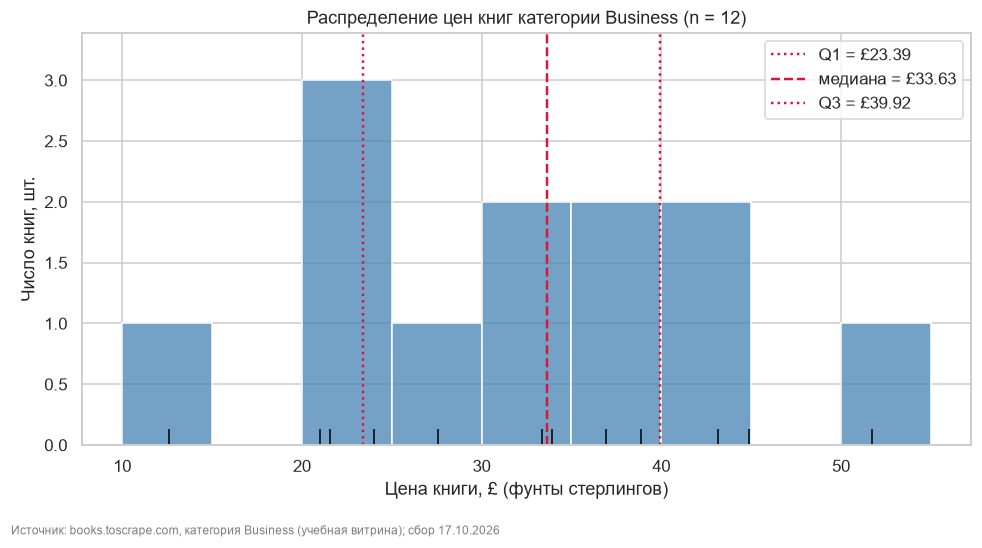

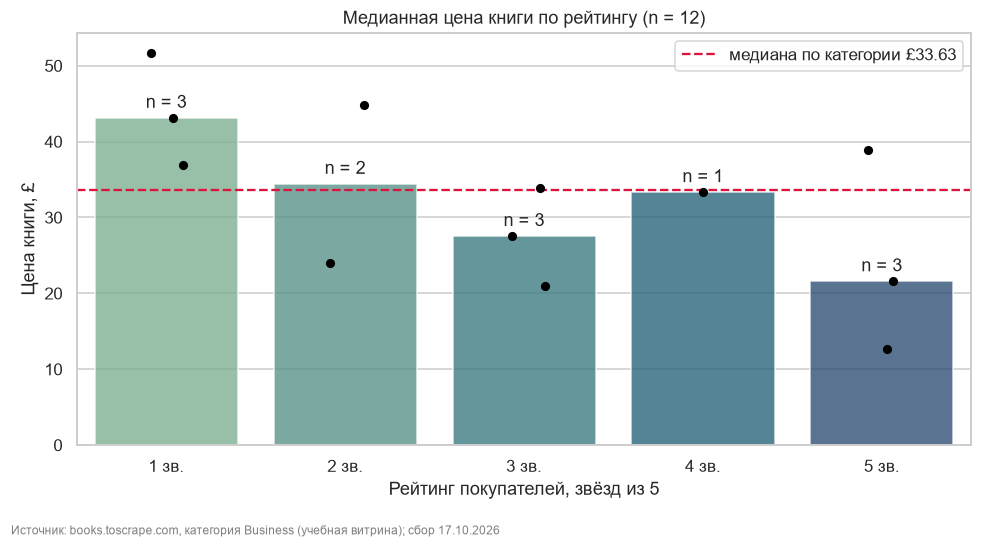

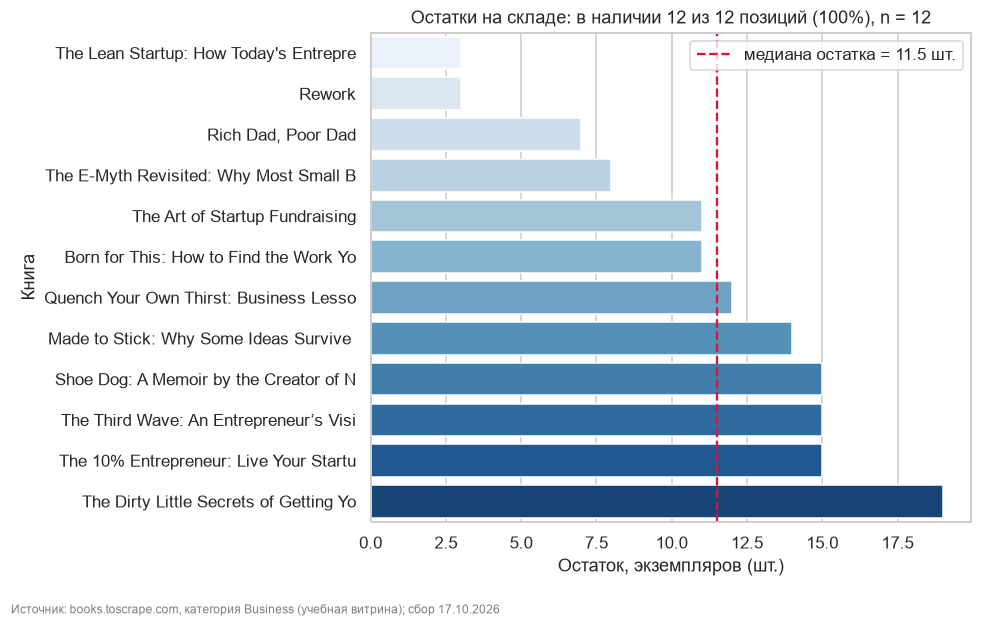

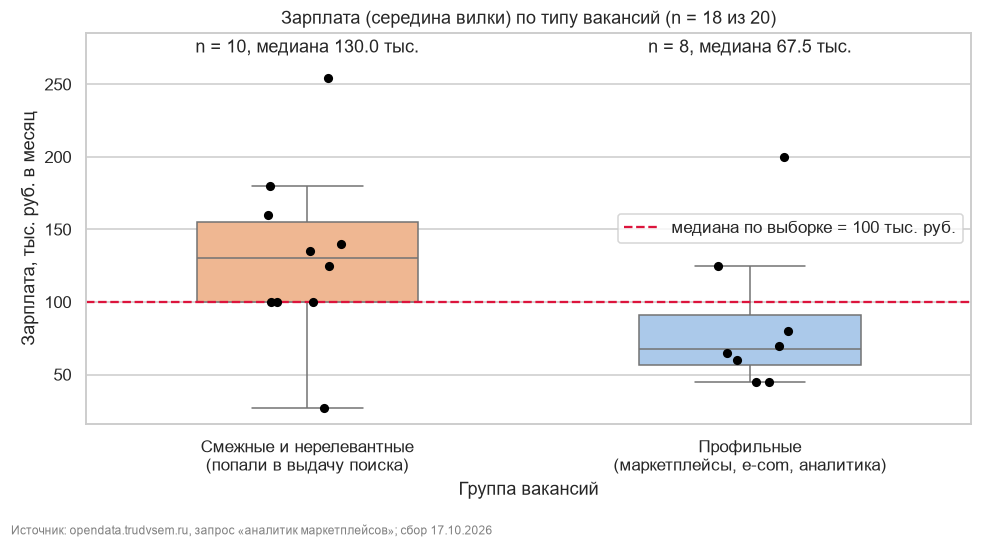

In [ ]:
#@title Шаг 5. Разведочный анализ и визуализация (задание) { display-mode: "form" }
# ------------------------------------------------------------------ TODO 5.1 ✅ ВЫПОЛНЕНО
# Метрики варианта 2: «Распределение цен, медиана по рейтингу, доля товаров в наличии,
# boxplot зарплат» → четыре графика ниже, у каждого заголовок с n, оси с единицами, источник.
SOURCE_WEB = f"Источник: books.toscrape.com, категория Business (учебная витрина); сбор {COLLECTED_AT:%d.%m.%Y}"
SOURCE_API = (f"Источник: opendata.trudvsem.ru, запрос «{CFG['api_params']['text']}»; "
              f"сбор {COLLECTED_AT:%d.%m.%Y}")
FIG_SIZE = (9, 4.8)
PRICE_BIN_WIDTH = 5                   # ширина интервала гистограммы, £
QUARTILES = [0.25, 0.5, 0.75]
RUB_IN_THOUSAND = 1000                # зарплаты на графике — в тыс. руб.
TITLE_MAX_LEN = 38                    # обрезка длинных названий книг на оси
ACCENT = "crimson"
LABEL_HEADROOM = 1.06              # запас по оси Y под подписи групп


def add_source(fig, text):
    """Подпись источника и даты сбора под графиком."""
    fig.text(0.01, -0.03, text, fontsize=8, color="gray", ha="left")


# --- Сводные таблицы: агрегируем в pandas, рисуем маленькие итоговые таблицы
prices = df_web["price"].dropna()
q1, med, q3 = prices.quantile(QUARTILES)
display(prices.describe().to_frame("цена, £").T.round(2))

plot_web = df_web.dropna(subset=["price", "rating"]).assign(
    rating_label=lambda d: d["rating"].astype(int).astype(str) + " зв.")
rating_order = sorted(plot_web["rating_label"].unique())
by_rating = (plot_web.groupby("rating_label")["price"]
             .agg(median="median", q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75),
                  n="size")
             .reindex(rating_order).reset_index())
display(by_rating.round(2))

salaries = df_api.dropna(subset=["salary_mid"]).assign(
    salary_k=lambda d: d["salary_mid"] / RUB_IN_THOUSAND,
    group=lambda d: np.where(d["is_profile"], "Профильные\n(маркетплейсы, e-com, аналитика)",
                             "Смежные и нерелевантные\n(попали в выдачу поиска)"))
group_order = sorted(salaries["group"].unique(), reverse=True)
by_group = (salaries.groupby("group")["salary_mid"]
            .agg(n="size", median="median", q1=lambda s: s.quantile(.25),
                 q3=lambda s: s.quantile(.75), min="min", max="max")
            .reindex(group_order))
display(by_group.round(0))

# --- График 1. Распределение цен каталога с медианой и квартилями
fig, ax = plt.subplots(figsize=FIG_SIZE)
bins = np.arange(np.floor(prices.min() / PRICE_BIN_WIDTH) * PRICE_BIN_WIDTH,
                 prices.max() + PRICE_BIN_WIDTH, PRICE_BIN_WIDTH)
sns.histplot(prices, bins=bins, color="steelblue", edgecolor="white", ax=ax)
sns.rugplot(prices, color="black", height=0.04, ax=ax)
for value, label, style in ((q1, "Q1", ":"), (med, "медиана", "--"), (q3, "Q3", ":")):
    ax.axvline(value, color=ACCENT, linestyle=style, linewidth=1.6, label=f"{label} = £{value:.2f}")
ax.set(title=f"Распределение цен книг категории Business (n = {len(prices)})",
       xlabel="Цена книги, £ (фунты стерлингов)", ylabel="Число книг, шт.")
ax.legend()
add_source(fig, SOURCE_WEB)
plt.tight_layout()
plt.show()

# --- График 2. Медианная цена по рейтингу (столбцы) и отдельные книги (точки)
fig, ax = plt.subplots(figsize=FIG_SIZE)
sns.barplot(data=by_rating, x="rating_label", y="median", hue="rating_label", order=rating_order,
            palette="crest", legend=False, alpha=0.8, ax=ax)
sns.stripplot(data=plot_web, x="rating_label", y="price", order=rating_order, color="black",
              size=6, jitter=0.12, ax=ax)
ax.axhline(med, color=ACCENT, linestyle="--", label=f"медиана по категории £{med:.2f}")
for pos, row in by_rating.iterrows():
    ax.annotate(f"n = {row['n']}", (pos, row["median"]), ha="center", va="bottom",
                xytext=(0, 4), textcoords="offset points")
ax.set(title=f"Медианная цена книги по рейтингу (n = {len(plot_web)})",
       xlabel="Рейтинг покупателей, звёзд из 5", ylabel="Цена книги, £")
ax.legend(loc="upper right")
add_source(fig, SOURCE_WEB)
plt.tight_layout()
plt.show()

# --- График 3. Наличие: доля позиций в наличии и остаток по каждой книге
stock_plot = (df_web.dropna(subset=["stock"])
              .assign(short_title=lambda d: d["title"].str.slice(0, TITLE_MAX_LEN))
              .sort_values("stock"))
in_stock_share = df_web["in_stock"].mean()
stock_median = stock_plot["stock"].median()
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=stock_plot, y="short_title", x="stock", hue="short_title", palette="Blues",
            legend=False, ax=ax)
ax.axvline(stock_median, color=ACCENT, linestyle="--", label=f"медиана остатка = {stock_median:.1f} шт.")
ax.set(title=(f"Остатки на складе: в наличии {df_web['in_stock'].sum()} из {len(df_web)} позиций "
              f"({in_stock_share:.0%}), n = {len(stock_plot)}"),
       xlabel="Остаток, экземпляров (шт.)", ylabel="Книга")
ax.legend(loc="upper right")
add_source(fig, SOURCE_WEB)
plt.tight_layout()
plt.show()

# --- График 4. Boxplot зарплат: профильные и прочие вакансии из выдачи
fig, ax = plt.subplots(figsize=FIG_SIZE)
sns.boxplot(data=salaries, x="group", y="salary_k", hue="group", order=group_order,
            palette="pastel", legend=False, width=0.5, showfliers=False, ax=ax)
sns.stripplot(data=salaries, x="group", y="salary_k", order=group_order, color="black",
              size=6, jitter=0.1, ax=ax)
ax.axhline(salaries["salary_k"].median(), color=ACCENT, linestyle="--",
           label=f"медиана по выборке = {salaries['salary_k'].median():.0f} тыс. руб.")
for pos, group in enumerate(group_order):
    ax.annotate(f"n = {by_group.loc[group, 'n']}, медиана {by_group.loc[group, 'median'] / RUB_IN_THOUSAND:.1f} тыс.",
                (pos, salaries["salary_k"].max() * LABEL_HEADROOM), ha="center", va="bottom")
ax.set_ylim(top=salaries["salary_k"].max() * LABEL_HEADROOM ** 2)
ax.set(title=f"Зарплата (середина вилки) по типу вакансий (n = {len(salaries)} из {len(df_api)})",
       xlabel="Группа вакансий", ylabel="Зарплата, тыс. руб. в месяц")
ax.legend(loc="center right")
add_source(fig, SOURCE_API)
plt.tight_layout()
plt.show()


**Как читать вывод.** Анализируйте те показатели, которые перечислены в `CFG["metrics"]` для **вашего** варианта. Для цен и зарплат уместны распределения, медианы и квартили; для репозиториев — звёзды и форки; для валют — динамика и волатильность; для погоды — временные ряды и рисковые дни; для публикаций — годы, цитируемость и организации. На каждом графике указывайте источник, число наблюдений (`n`), единицы измерения и ограничения выборки. Не переносите метрики из других вариантов и не создавайте отсутствующие в источнике признаки.


> 💬 **Комментарий к выполнению — шаг 5 (TODO 5.1): четыре графика по метрикам варианта 2**
>
> У каждого графика есть заголовок с объёмом выборки `n`, подписи осей с единицами (£, шт., тыс. руб./мес), опорная линия (медиана или квартили) и подпись источника с датой сбора. Seaborn вызывается в современном варианте API: `hue=...`, `legend=False`.
>
> 1. **Распределение цен** (n = 12). Медиана **£33.63**, Q1–Q3 = **£23.39–39.92** (IQR £16.53), диапазон £12.61–51.74.
> 2. **Медиана цены по рейтингу.** Связь обратная: книги с 1 звездой — медиана £43.14 (n = 3), с 5 звёздами — £21.59 (n = 3). В каждой группе 1–3 книги, поэтому это **наблюдение, а не закономерность**.
> 3. **Наличие.** В наличии 12 из 12 позиций (100 %). Остаток — от 3 до 19 шт., медиана 11,5 шт.
> 4. **Boxplot зарплат.** Медиана профильных вакансий **67 500 руб.** (n = 8, Q1–Q3 56 250–91 250). У смежных вакансий из выдачи медиана 130 000 руб. (n = 10): это руководители и продавцы. Поэтому общая медиана 100 000 руб. из шага 6 **завышена** и для бюджета найма не подходит.


### Шаг 6. Выводы и управленческие рекомендации

**Зачем мы это делаем.** Заказчику нужны не графики, а решения: входить ли в нишу, по какой цене, хватит ли на рынке специалистов. Метрики считаем кодом, а в текст переносим уже посчитанные значения — так вывод невозможно «придумать».

In [ ]:
#@title Шаг 6. Метрики для выводов: считаем, а не придумываем { display-mode: "form" }
def safe(series, func, default=float("nan")):
    """Вычислить показатель для существующего числового поля."""
    s = pd.to_numeric(series, errors="coerce").dropna() if series is not None else pd.Series(dtype=float)
    return func(s) if len(s) else default

metrics = {
    "Вариант": CFG["id"],
    "Записей API": len(df_api),
    "HTML-объектов": len(df_web),
}
# Добавляем только показатели, чьи столбцы реально существуют после очистки.
if "price" in df_web:
    metrics["Медианная цена"] = safe(df_web["price"], lambda s: round(s.median(), 2))
    metrics["Разброс цен (IQR)"] = safe(
        df_web["price"], lambda s: round(s.quantile(.75) - s.quantile(.25), 2))
if "stock" in df_web:
    stock_values = pd.to_numeric(df_web["stock"], errors="coerce")
    metrics["Доля позиций в наличии"] = round(float(stock_values.dropna().gt(0).mean()), 3) if stock_values.notna().any() else float("nan")
if "rating" in df_web:
    metrics["Средний рейтинг"] = safe(df_web["rating"], lambda s: round(s.mean(), 2))
if CFG["api"] == "trudvsem" and "salary_mid" in df_api:
    metrics["Медиана зарплатной вилки"] = safe(df_api["salary_mid"], lambda s: round(s.median(), 2))
    metrics["Доля вакансий с зарплатой"] = round(float(df_api["salary_mid"].notna().mean()), 3) if len(df_api) else float("nan")
if CFG["api"] == "trudvsem" and "is_remote" in df_api:
    metrics["Доля удалённых вакансий"] = safe(df_api["is_remote"], lambda s: round(s.astype(float).mean(), 3))

summary = pd.Series(metrics, name="значение").to_frame()
display(summary)

print(f"Источники: API — {API_SOURCE}; сайт — {WEB_SOURCE}. "
      f"Запросов в журнале: {len(REQUEST_LOG)}, с ошибкой: "
      f"{sum(1 for m in REQUEST_LOG if m.get('error'))}.")
print("Проверьте также специфические показатели и минимум четыре графика своего варианта (CFG['metrics']).")
if API_SOURCE in ("synthetic", "offline-snapshot") or WEB_SOURCE in ("synthetic", "offline-snapshot"):
    print("⚠ Есть аварийные данные: пометьте их в отчёте и не выдавайте за реальные рыночные наблюдения.")


,значение
Вариант,2.00
Записей API,20.00
HTML-объектов,12.00
Медианная цена,33.63
Разброс цен (IQR),16.53
Доля позиций в наличии,1.00
Средний рейтинг,2.92
Медиана зарплатной вилки,100000.00
Доля вакансий с зарплатой,0.90


Источники: API — trudvsem; сайт — books. Запросов в журнале: 16, с ошибкой: 1.
Проверьте также специфические показатели и минимум четыре графика своего варианта (CFG['metrics']).


In [ ]:
#@title Шаг 6.1 (дополнение). Показатели варианта 2 для выводов { display-mode: "form" }
# ✅ ДОБАВЛЕНО: специфические метрики варианта, на которые опираются выводы ниже.
profile_sal = df_api.loc[df_api["is_profile"], "salary_mid"].dropna()
other_sal = df_api.loc[~df_api["is_profile"], "salary_mid"].dropna()
skill_counts = Counter(skill for skills in df_api["skills"] for skill in skills)
profile_by_region = (df_api[df_api["is_profile"]].groupby("region_group")["salary_mid"].median())
lowest_stock = df_web.loc[df_web["stock"].idxmin()]
HIGH_RATING = 4                       # «высокий» рейтинг — 4–5 звёзд

variant_metrics = {
    "Дата сбора": f"{COLLECTED_AT:%d.%m.%Y}",
    "Цена книги: Q1 / медиана / Q3, £": f"{q1:.2f} / {med:.2f} / {q3:.2f}",
    "Цена книги: мин / макс, £": f"{prices.min():.2f} / {prices.max():.2f}",
    "Медиана цены по рейтингу, £": "; ".join(
        f"{r.rating_label}: {r.median:.2f} (n={r.n})" for r in by_rating.itertuples()),
    "Доля позиций в наличии (листинг)": f"{df_web['in_stock'].mean():.0%}",
    "Остаток, шт.: мин / медиана / макс": (f"{df_web['stock'].min()} / {df_web['stock'].median():.1f}"
                                          f" / {df_web['stock'].max()}"),
    "Минимальный остаток": f"{lowest_stock['title']} — {lowest_stock['stock']} шт.",
    "Книг дороже медианы с рейтингом 4–5 зв.": (f"{int(((df_web['price'] > med) & (df_web['rating'] >= HIGH_RATING)).sum())}"
                                              f" из {int((df_web['rating'] >= HIGH_RATING).sum())}"),
    "Вакансий всего / профильных": f"{len(df_api)} / {int(df_api['is_profile'].sum())}",
    "Вакансий с указанной зарплатой": f"{df_api['salary_mid'].notna().sum()} из {len(df_api)}",
    "Медиана зарплаты, профильные, руб.": f"{profile_sal.median():,.0f} (n={len(profile_sal)})".replace(",", " "),
    "Q1–Q3 зарплаты, профильные, руб.": (f"{profile_sal.quantile(.25):,.0f} – "
                                        f"{profile_sal.quantile(.75):,.0f}").replace(",", " "),
    "Медиана зарплаты, прочие, руб.": f"{other_sal.median():,.0f} (n={len(other_sal)})".replace(",", " "),
    "Медиана зарплаты профильных: Москва и МО / регионы, руб.": " / ".join(
        f"{profile_by_region.get(g, float('nan')):,.0f}".replace(",", " ")
        for g in ("Москва и МО", "Другие регионы")),
    "Доля вакансий в Москве и МО": f"{(df_api['region_group'] == 'Москва и МО').mean():.0%}",
    "Навыки в тексте требований (RegEx)": ", ".join(f"{k}: {v}" for k, v in skill_counts.most_common(6)),
}
display(pd.Series(variant_metrics, name="значение").to_frame())

print("Профильные вакансии:")
display(df_api.loc[df_api["is_profile"], ["job_name", "region", "salary_min", "salary_max",
                                          "experience_years"]].sort_values("salary_min"))


,значение
Дата сбора,17.10.2026
"Цена книги: Q1 / медиана / Q3, £",23.39 / 33.63 / 39.92
"Цена книги: мин / макс, £",12.61 / 51.74
"Медиана цены по рейтингу, £",1 зв.: 43.14 (n=3); 2 зв.: 34.44 (n=2); 3 зв.:...
Доля позиций в наличии (листинг),100%
"Остаток, шт.: мин / медиана / макс",3 / 11.5 / 19
Минимальный остаток,The Lean Startup: How Today's Entrepreneurs Us...
Книг дороже медианы с рейтингом 4–5 зв.,1 из 4
Вакансий всего / профильных,20 / 9
Вакансий с указанной зарплатой,18 из 20


Профильные вакансии:


,job_name,region,salary_min,salary_max,experience_years
2,Контент-менеджер по маркетплейсам,Город Москва,30000.0,60000.0,4
0,аналитик по маркетплейсам,Ивановская область,45000.0,45000.0,1
9,Менеджер по развитию продаж на маркетплейсах,Смоленская область,60000.0,60000.0,1
4,Менеджер по работе с маркетплейсами,Ульяновская область,60000.0,70000.0,0
1,Специалист по работе с онлайн дилерами,Город Москва,70000.0,70000.0,2
3,Аналитик данных,Воронежская область,80000.0,80000.0,3
7,Специалист по интернет-торговле,Московская область,100000.0,150000.0,1
12,Начальник отдела электронной коммерции,Город Москва,200000.0,200000.0,2
8,Менеджер по продажам /Менеджер по работе с мар...,Город Москва,NaN,NaN,3


**Как читать вывод.** Таблица метрик — фактура для отчёта. Проверьте строку об источниках: если хотя бы один из них аварийный, выводы помечаются как предварительные. Ниже — шаблон управленческого вывода: каждая рекомендация должна опираться на конкретное число из этой таблицы и содержать действие, а не наблюдение.

### Ваши выводы и рекомендации

Заполните шаблон на основе собственных данных и показателей, указанных в `CFG["metrics"]`. Вывод «ситуация улучшается» без числа и управленческого действия не засчитывается.

**1. Что собрано.** API и HTML-источники, число **уникальных** записей, дата сбора, параметры запроса, ограничения пагинации и доступности. Если объём меньше ориентира (50 API / 40 HTML), объясните объективную причину и покажите, что собраны все доступные записи.

**2. Что показывают данные.** Три–пять наблюдений с расчётами именно своего варианта: например, цены и остатки, востребованность технологий в репозиториях, динамика курсов, погода и логистические риски, научные публикации или вакансии. Зарплаты и навыки не требуются, если их нет в предметной области варианта.

**3. Управленческие рекомендации.** Две–три рекомендации в формате «действие — численное основание — ожидаемый эффект — как проверить». Отделяйте результат наблюдения от предположения о будущем эффекте.

**4. Ограничения и риски.** Размер и смещение выборки, доля пропусков, лимиты и доступность API, ограничения учебного HTML-сайта, единичный срез вместо динамики. Синтетические и аварийные данные не выдавайте за реальные рыночные результаты.

**5. Что делать дальше.** Какие данные следует добрать и как часто повторять сбор для проверки рекомендаций.


### 💬 Выводы и рекомендации — вариант 2

**1. Что собрано.**
* **API «Работа в России»:** запрос «аналитик маркетплейсов» (`limit = 100`, `offset` — номер страницы). Получено **20 уникальных вакансий** — все, что вернул портал (`meta.total = 20`). Пагинация остановилась на первой, неполной странице.
* **HTML `books.toscrape.com`, категория Business:** **12 книг** — вся категория, страница 2 отвечает 404. Дополнительно загружены 12 страниц товаров для точного остатка.
* Ориентиры 50 и 40 не достигнуты по объективной причине (размер источника). Это обосновано в выводах по шагам выполнения работы. Записи не дублировались, вариант не менялся.
* Синтетические и аварийные данные в основной части **не использовались**. Единственный искусственный пример — контрольный тест функции сравнения в задании D, он явно помечен.

**2. Что показывают данные.**
1. **Цены конкурента.** Медиана **£33.63**, половина ассортимента — в коридоре **£23.39–39.92**, крайние значения £12.61 и £51.74.
2. **Премии за рейтинг нет.** Медиана цены книг с 5 звёздами — £21.59, с 1 звездой — £43.14. Из 4 книг с рейтингом 4–5 звёзд дороже медианы только 1. Выборка мала (1–3 книги на группу), поэтому это гипотеза для проверки, а не вывод.
3. **Наличие.** 100 % позиций в наличии, медианный остаток 11,5 шт., минимальный — 3 шт. («The Lean Startup» и «Rework»). Дефицита ассортимента в категории у конкурента нет.
4. **Кадры.** Профильных вакансий **9 из 20** (45 %). Медиана зарплаты профильных — **67 500 руб./мес** (n = 8, Q1–Q3 56 250–91 250). В Москве и МО — 97 500 руб., в регионах — 62 500 руб. На Москву и МО приходится 75 % всей выдачи.
5. **Требования.** В текстах вакансий чаще всего встречаются «маркетплейс» (19 из 20), Excel (12) и Ozon (12). Важно знание конкретных площадок, а не BI-стека.

**3. Управленческие рекомендации** (действие — основание — ожидаемый эффект — проверка).
1. **Базовую цену деловой литературы ставить в коридоре £23–34 (от Q1 до медианы конкурента).** Основание: медиана £33.63, Q1 £23.39. Ожидаемый эффект (предположение): цена не выше половины ассортимента конкурента без демпинга ниже Q1. Проверка: еженедельный мониторинг цен (механизм задания D) и сравнение конверсии в течение 4 недель.
2. **Не закладывать наценку за высокий рейтинг; использовать рейтинг в продвижении.** Основание: у конкурента книги с 5 звёздами дешевле (медиана £21.59 против £43.14 у книг с 1 звездой). Эффект: не завышать цену хитов. Проверка: собрать весь каталог (около 1000 книг) и посчитать ранговую корреляцию «рейтинг — цена»; при |ρ| < 0,1 рекомендация подтверждается.
3. **Бюджет на аналитика маркетплейсов — от 67 500 руб./мес; рассмотреть найм в регионах.** Основание: медиана профильных вакансий 67 500 руб.; в регионах 62 500 руб., в Москве и МО 97 500 руб. Ориентир по общей выборке (100 000 руб.) завышен нерелевантными вакансиями. Эффект (предположение): экономия ФОТ около трети по сравнению со столичной ставкой. Проверка: число откликов и срок закрытия вакансии (цель — не больше 30 дней) при ставке на уровне медианы. В требованиях к кандидату указывать опыт работы с Ozon и Wildberries и уверенный Excel.

**4. Ограничения и риски.**
* Малые выборки (12 книг, 20 вакансий, из них 8 профильных с зарплатой). Все медианы — ориентир, а не статистически значимый результат.
* `books.toscrape.com` — **учебная витрина**: цены в £ и остатки условные. Повторный сбор в задании D не показал ни одного изменения, то есть данные статичны. Выводы о ценах — **демонстрация метода, а не подтверждённый рыночный результат**.
* «Работа в России» покрывает только вакансии, размещённые на портале (без hh.ru и других агрегаторов). Полнотекстовый поиск шумный, а профильность определена эвристикой по названию.
* «от X» — только нижняя граница вилки: у 30 % вакансий верхней границы нет. Есть одна пара вакансий одного работодателя с одинаковым текстом.
* Это единичный срез на 17.10.2026, а не динамика.

**5. Что делать дальше.**
* Собрать весь каталог `books.toscrape.com` (50 страниц) для проверки связи цены и рейтинга.
* Расширить запрос синонимами («специалист по маркетплейсам», «менеджер маркетплейсов», «e-commerce аналитик») с дедупликацией по `id` (довести выборку до 50+).
* Повторять сбор еженедельно 4–8 недель по механизму задания D.
* При наличии авторизации добавить hh.ru API для сверки зарплат.


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель. Параметры подставляются в код автоматически по значению `VARIANT` из шага 1. Вариант 30 разобран в версии для преподавателя как эталон.

**Ориентир объёма:** не менее **50 уникальных записей из API** и **40 HTML-объектов**. Если выбранный источник или параметры варианта объективно дают меньше, соберите все доступные уникальные записи и обоснуйте ограничение. Не дублируйте записи ради порога и не меняйте назначенный вариант без согласования. Для Open-Meteo объём может зависеть от числа городов и дней прогноза, для сайтов с тегами — от числа доступных карточек.

| № | Сфера | Бизнес-задача | Источник API | Сайт для парсинга | Параметры сбора | Целевые метрики и визуализации |
|---:|---|---|---|---|---|---|
| 1 | HR-аналитика | Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят | opendata.trudvsem.ru | books.toscrape.com | API: text=инженер машинного обучения, pages=5, per_page=100<br>Сайт: category=science_22, pages=3 | Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога |
| 2 | E-commerce | Ценовое позиционирование в нише деловой литературы | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик маркетплейсов, pages=4, per_page=100<br>Сайт: category=business_35, pages=3 | Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат |
| 3 | Финтех | Валютный риск закупок: динамика USD и EUR за квартал | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=90<br>Сайт: category=travel_2, pages=2 | Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли |
| 4 | Мониторинг конкурентов | Сравнение ассортимента двух товарных категорий | api.github.com | books.toscrape.com | API: q=price monitoring, sort=stars, pages=2, per_page=50<br>Сайт: category=fiction_10, pages=4 | Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки» |
| 5 | Наука и инновации | Научная активность в сфере FinTech: динамика публикаций | api.openalex.org | quotes.toscrape.com | API: search=fintech, from_year=2019, per_page=100, pages=2<br>Сайт: tag=inspirational, pages=4 | Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов |
| 6 | Логистика | Погодные риски на складских хабах: планирование окон отгрузки | api.open-meteo.com | books.toscrape.com | API: cities=['Москва', 'Екатеринбург', 'Новосибирск'], days=14<br>Сайт: category=history_32, pages=2 | Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога |
| 7 | HR-аналитика | Спрос на дата-инженеров и требования к стеку | opendata.trudvsem.ru | quotes.toscrape.com | API: text=инженер данных, pages=5, per_page=100<br>Сайт: tag=life, pages=3 | Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат |
| 8 | E-commerce | Влияние рейтинга на цену: есть ли премия за качество | api.github.com | books.toscrape.com | API: q=recommender system, sort=stars, pages=2, per_page=50<br>Сайт: category=romance_8, pages=4 | Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев |
| 9 | Финтех | Стоимость валютной корзины импортёра | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['USD', 'EUR', 'CNY'], days=120<br>Сайт: section=computers/laptops, pages=3 | Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу |
| 10 | Мониторинг конкурентов | Глубина ассортимента и «дыры» в наличии у конкурента | opendata.trudvsem.ru | books.toscrape.com | API: text=категорийный менеджер, pages=4, per_page=100<br>Сайт: category=mystery_3, pages=4 | Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям |
| 11 | Наука и инновации | Публикационный ландшафт по теме «supply chain analytics» | api.openalex.org | scrapethissite.com/pages | API: search=supply chain analytics, from_year=2020, per_page=100, pages=2<br>Сайт: section=countries, pages=1 | Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран |
| 12 | Логистика | Температурный режим перевозок: risk-календарь на две недели | api.open-meteo.com | webscraper.io/test-sites/e-commerce/allinone | API: cities=['Санкт-Петербург', 'Казань', 'Краснодар'], days=14<br>Сайт: section=computers/tablets, pages=3 | Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов |
| 13 | HR-аналитика | BI-аналитики: сколько стоит и что требуют работодатели | opendata.trudvsem.ru | books.toscrape.com | API: text=BI аналитик, pages=5, per_page=100<br>Сайт: category=business_35, pages=3 | Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости |
| 14 | Технологические тренды | Экосистема инструментов парсинга: кто лидирует | api.github.com | quotes.toscrape.com | API: q=web scraping, sort=stars, pages=2, per_page=50<br>Сайт: tag=books, pages=3 | Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды |
| 15 | E-commerce | Ценовые сегменты в детской нише: где «дыра» в предложении | opendata.trudvsem.ru | books.toscrape.com | API: text=менеджер интернет-магазина, pages=4, per_page=100<br>Сайт: category=childrens_11, pages=4 | Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей |
| 16 | Финтех | Курс юаня и импорт электроники: чувствительность цены | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['CNY'], days=180<br>Сайт: section=phones/touch, pages=2 | Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса |
| 17 | Наука и инновации | Исследования по «digital twin» в промышленности | api.openalex.org | books.toscrape.com | API: search=digital twin manufacturing, from_year=2018, per_page=100, pages=2<br>Сайт: category=science_22, pages=3 | Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости |
| 18 | Мониторинг конкурентов | Сравнение цен и «звёздности» ассортимента двух категорий | api.github.com | books.toscrape.com | API: q=e-commerce analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=food-and-drink_33, pages=3 | Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики |
| 19 | HR-аналитика | Логистические профессии: дефицит кадров по регионам | opendata.trudvsem.ru | scrapethissite.com/pages | API: text=логист, pages=6, per_page=100<br>Сайт: section=countries, pages=1 | Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн) |
| 20 | Логистика | Окна доставки в северных хабах на горизонте 16 дней | api.open-meteo.com | books.toscrape.com | API: cities=['Мурманск', 'Архангельск', 'Якутск'], days=16<br>Сайт: category=travel_2, pages=2 | Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза |
| 21 | E-commerce | Автоматизация мониторинга: как часто меняется наличие товара | api.github.com | books.toscrape.com | API: q=price tracker, sort=stars, pages=2, per_page=50<br>Сайт: category=sequential-art_5, pages=4 | Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен |
| 22 | Финтех | Волатильность рубля как фактор ценообразования | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=365<br>Сайт: category=business_35, pages=3 | Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 % |
| 23 | HR-аналитика | Продуктовые аналитики: требования и вилки | opendata.trudvsem.ru | quotes.toscrape.com | API: text=продуктовый аналитик, pages=5, per_page=100<br>Сайт: tag=humor, pages=3 | Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты |
| 24 | Технологические тренды | Инструменты работы с данными: Python-экосистема | api.github.com | webscraper.io/test-sites/e-commerce/allinone | API: q=pandas alternative dataframe, sort=stars, pages=2, per_page=50<br>Сайт: section=computers/laptops, pages=3 | Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx) |
| 25 | Наука и инновации | Публикации по «marketplace pricing»: кто задаёт повестку | api.openalex.org | books.toscrape.com | API: search=marketplace pricing, from_year=2019, per_page=100, pages=2<br>Сайт: category=business_35, pages=3 | Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога |
| 26 | Логистика | Планирование складских смен по погодным окнам | api.open-meteo.com | scrapethissite.com/pages | API: cities=['Ростов-на-Дону', 'Самара', 'Пермь'], days=14<br>Сайт: section=hockey, pages=2 | Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией |
| 27 | Мониторинг конкурентов | Бенчмарк цен на технику: разброс внутри линейки | opendata.trudvsem.ru | webscraper.io/test-sites/e-commerce/allinone | API: text=менеджер по закупкам, pages=4, per_page=100<br>Сайт: section=computers/laptops, pages=3 | Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков |
| 28 | E-commerce | Влияние глубины каталога на средний чек (гипотеза) | api.github.com | books.toscrape.com | API: q=shopping cart analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=poetry_23, pages=4 | Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев |
| 29 | Финтех | Кросс-курсы и арбитраж: USD, EUR, CNY за полгода | cbr.ru | quotes.toscrape.com | API: currencies=['USD', 'EUR', 'CNY'], days=180<br>Сайт: tag=life, pages=3 | Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат |
| 30 | E-commerce + HR (эталон преподавателя) | Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик данных, pages=3, per_page=100<br>Сайт: category=business_35, pages=3 | Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков |

## Критерии оценивания — максимум 10 баллов

Четыре блока по 25 из 100 условных единиц исходной рубрики соответствуют **четырём блокам по 2,5 балла** в Moodle. Оценку выставляет преподаватель по фактическому выполнению применимых требований, а не по одному числу автоматических проверок.

| Блок | Что оценивается | Максимум |
|---|---|---:|
| 1. Сбор данных | Корректная пагинация и остановка; паузы, повторные попытки, обработка HTTP-ответов и исключений; полнота **доступной уникальной** выборки, журнал сбора и объяснение объективных ограничений объёма | **2,5** |
| 2. Очистка, RegEx и XPath | Работающие CSS-селекторы и XPath со сверкой; обязательные общие RegEx-функции и тесты; распознавание ≥ 80% **применимых** значений; корректные типы столбцов `DataFrame` | **2,5** |
| 3. EDA и визуализация | Не менее четырёх содержательных графиков **по своему варианту**; названия, подписи осей, единицы измерения и объём выборки; подходящие метрики, читаемость | **2,5** |
| 4. Бизнес-выводы | Выводы с опорой на рассчитанные значения; конкретные действия, ожидаемый эффект и способ проверки; корректно указанные ограничения | **2,5** |
| **Итого** | | **10** |

### Шкала оценивания

| Баллы | Оценка |
|---|---|
| От 8 до 10 включительно | Отлично |
| От 7 до менее 8 | Хорошо |
| От 5 до менее 7 | Удовлетворительно |
| Менее 5 | Возврат на доработку |

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Ключ, токен или пароль в коде либо выводе ячейки | −1,5 и обязательный отзыв ключа |
| Сбор без пауз и обработки ошибок | −1,0 |
| Выводы по аварийным или синтетическим данным без указания этого факта | −1,0 |
| Разбор HTML регулярными выражениями вместо HTML-парсера | −0,5 |
| Код без комментариев, «магические числа», нарушения PEP 8 | −0,5 |
| Графики без заголовков, подписей осей и единиц измерения | −0,5 |
| Вместо ссылки сдан файл либо ноутбук размещён без выводов ячеек | −1,0 |

**Неприменимые предметные проверки не снижают оценку.** Общие учебные RegEx-функции и их тесты, работа с API, HTML, EDA и выводы обязательны для всех вариантов. Если источник объективно меньше ориентира по объёму, обоснуйте это: преподаватель оценивает полноту доступных данных.

**Задание со звёздочкой:** можно получить **до +1,0 балла**, но **общий максимум по ПР1 — 10 баллов**. Дополнительный балл учитывается только при наличии выполненной основной работы; итог считается как `min(10; max(0; основные баллы − штрафы + бонус))`. Бонус не компенсирует отсутствие обязательных разделов.


In [ ]:
#@title Самопроверка перед сдачей: с учётом вашего варианта { display-mode: "form" }
# Заполните только если источник объективно не позволяет достичь объёма выборки.
# Пустое или формальное объяснение НЕ освобождает от требования.
# ✅ ЗАПОЛНЕНО: оба источника варианта 2 объективно меньше ориентира.
# Почему выборка меньше и почему это не ошибка сбора:
#   • API: «Работа в России» сама сообщает meta.total = 20 вакансий по запросу варианта;
#     страница limit=100 пришла неполной (20 записей) — больше данных нет, страницы 1–3 пусты.
#   • HTML: в категории Business сайт показывает «12 results»; страница 2 отвечает 404,
#     то есть параметр варианта pages=3 — верхняя граница, а фактически страница одна.
#   • Собраны ВСЕ доступные уникальные записи (дублей по id/url нет). Дублировать записи
#     запрещено заданием; менять запрос или категорию — значит подменить вариант.
#   • Доказательства — в выводе шагов 2 и 3 (блоки «⚠ Объём ниже ориентира») и в таблице ниже.
API_LIMIT_REASON = "«Работа в России» по запросу «аналитик маркетплейсов» на 17.10.2026 возвращает meta.total = 20: первая страница (limit=100) неполная, собраны все 20 уникальных вакансий; дублировать записи нельзя, вариант не менялся."  #@param {type:"string"}
HTML_LIMIT_REASON = "Категория Business (business_35) на books.toscrape.com содержит 12 книг на одной странице (на сайте «12 results»), страницы 2–3 отвечают 404; собраны все 12 карточек и 12 страниц товаров."  #@param {type:"string"}

checks = []

def check(name, passed=False, hint="", applicable=True, needs_review=False):
    """Статус проверки: PASS / FAIL / NA / REVIEW."""
    if not applicable:
        status = "NA"
    elif needs_review:
        status = "REVIEW"
    else:
        status = "PASS" if bool(passed) else "FAIL"
    checks.append((name, status, hint))

def unique_rows(frame):
    """Подсчитываем уникальные записи по всем полям, включая вложенные значения."""
    if frame.empty:
        return 0
    fingerprints = frame.apply(
        lambda row: json.dumps(row.to_dict(), sort_keys=True, ensure_ascii=False, default=str),
        axis=1)
    return fingerprints.nunique()

def check_volume(name, actual, expected, explanation):
    """Отклонение по объёму не засчитывается автоматически без проверки преподавателя."""
    if actual >= expected:
        check(f"{name}: {actual} / ориентир {expected}", True)
    elif explanation.strip():
        check(f"{name}: {actual} / ориентир {expected}",
              hint="⚠ Укажите в выводах и обоснуйте преподавателю: " + explanation.strip(),
              needs_review=True)
    else:
        check(f"{name}: {actual} / ориентир {expected}", False,
              "Соберите все доступные уникальные записи либо укажите объективную причину ограничения")

api_data = globals().get("df_api", pd.DataFrame())
web_data = globals().get("df_web", pd.DataFrame())
api_kind = CFG["api"]
site_kind = CFG["site"]
selected_metrics = CFG["metrics"].lower()

check("Выбран назначенный преподавателем вариант 1–30",
      isinstance(VARIANT, int) and 1 <= VARIANT <= 30 and CFG["id"] == VARIANT,
      "Проверьте, что выбран именно ваш вариант, а не значение по умолчанию")
check_volume("Записи API (уникальные, без искусственного дублирования)",
             unique_rows(api_data), 50, API_LIMIT_REASON)
check_volume("HTML-объекты (уникальные)", unique_rows(web_data), 40, HTML_LIMIT_REASON)

# При одинаковом числе объектов их порядок и ключевые поля должны совпадать.
bs4_rows = globals().get("rows_bs4", [])
xpath_rows = globals().get("rows_xpath", [])
bs4_labels = [row.get("title") or row.get("text") for row in bs4_rows]
xpath_labels = [row.get("title") or row.get("text") for row in xpath_rows]
check("BeautifulSoup и XPath: совпадают число объектов и названия/текст",
      bool(bs4_labels) and len(bs4_labels) == len(xpath_labels) and
      all(a == b for a, b in zip(bs4_labels, xpath_labels)),
      "Сравните CSS и XPath по составу, количеству и значениям; без совпадения нельзя считать парсинг проверенным")

# Числовые признаки могут находиться либо в API, либо в HTML-источнике.
has_numeric = any(
    pd.api.types.is_numeric_dtype(frame[col])
    for frame in (api_data, web_data) for col in frame.columns
)
check("Подготовлены типизированные числовые показатели для анализа", has_numeric,
      "Приведите необходимые поля своего варианта к числовым типам")

# Цены имеют смысл для товарных витрин, но НЕ для цитат / справочников / научных публикаций.
price_applicable = site_kind in ("books", "webscraper")
price_present = "price" in web_data.columns
price_share = (pd.to_numeric(web_data["price"], errors="coerce").notna().mean()
               if len(web_data) and price_present else 0)
check("Распознано ≥ 80% применимых цен HTML-витрины", price_share >= 0.80,
      "Проверьте очистку поля price и долю корректных значений", applicable=price_applicable)

# Требования к зарплатам и навыкам применяются лишь для соответствующих вакансий.
salary_applicable = api_kind == "trudvsem" and bool(
    re.search(r"зарплат|вилк|стоимость кадров|опыту", selected_metrics + " " + CFG["task"].lower()))
skills_applicable = api_kind == "trudvsem" and bool(
    re.search(r"навык|технолог|требовани|стек", selected_metrics + " " + CFG["task"].lower()))
check("Обработано поле зарплаты вакансий", "salary_mid" in api_data.columns,
      "Для применимого варианта подготовьте столбец salary_mid, отсутствие зарплаты у вакансии отмечайте как NaN",
      applicable=salary_applicable)

skills_present = "skills" in api_data.columns and any(
    isinstance(value, (list, tuple, set)) and len(value) > 0
    or isinstance(value, str) and bool(value.strip())
    for value in api_data["skills"].dropna()
)
check("Извлечены навыки из текста требований вакансий", skills_present,
      "Если навыки предусмотрены заданием, примените extract_skills к реальному тексту требований",
      applicable=skills_applicable)

check("Выполнены тесты общих RegEx-функций", globals().get("REGEX_TESTS_OK", False),
      "Выполните шаг 4 целиком; общий набор тестов обязателен для всех вариантов")
check("Есть журнал запросов (паузы и повторы нужно проверить)",
      REQUEST_PAUSE >= 0.1 and bool(REQUEST_LOG),
      "Проверьте REQUEST_PAUSE, Retry-After и ограничения источника; одного журнала для доказательства корректности недостаточно")

secret_like = [key for key, value in list(globals().items())
               if isinstance(value, str) and re.match(r"^(ghp_|github_pat_|sk-|AIza)[A-Za-z0-9_\-]{10,}$", value)]
check("Не обнаружены типовые токены в строковых переменных", not secret_like,
      "Удалите обнаруженные секреты; отдельно проверьте весь код и выводы перед публикацией")
check("Не использованы аварийные или синтетические данные вместо реальных",
      API_SOURCE not in ("synthetic", "offline-snapshot") and
      WEB_SOURCE not in ("synthetic", "offline-snapshot"),
      "Если источник недоступен, обязательно отметьте это в выводах и не делайте рыночных утверждений")

marks = {"PASS": "✅", "FAIL": "❌", "NA": "➖", "REVIEW": "⚠"}
counts = {status: sum(item[1] == status for item in checks) for status in marks}
print(f"Вариант {CFG['id']} ({api_kind} / {site_kind})")
print(f"✅ Выполнено: {counts['PASS']} | ❌ Исправить: {counts['FAIL']} | "
      f"➖ Не применяется: {counts['NA']} | ⚠ Требует проверки: {counts['REVIEW']}\n")
for name, status, hint in checks:
    print(f"  {marks[status]} {name}" + (f" — {hint}" if status in ("FAIL", "REVIEW") and hint else ""))
print("\nСамопроверка — подсказка, а не автоматическое начисление или снятие баллов.")
print("Проверьте вручную: ≥ 4 графика, выводы, применимые метрики, отсутствие секретов и ссылку GitHub.")
if counts["REVIEW"]:
    print("⚠ Причины ограничения выборки должен оценить преподаватель: автоматического зачёта нет.")

# ✅ ДОБАВЛЕНО: сводное обоснование объёма — ориентир, собрано, доступно в источнике, причина.
volume_table = pd.DataFrame([
    {"источник": f"API {API_TITLES[api_kind].split(' —')[0]}",
     "ориентир": API_MIN_RECORDS, "собрано уникальных": unique_rows(api_data),
     "доступно в источнике": API_VOLUME.get("reported_total"),
     "подтверждение": f"meta.total = {API_VOLUME.get('reported_total')}; страница limit="
                      f"{API_VOLUME.get('per_page')} вернула {API_VOLUME.get('last_batch')} записей",
     "обоснование": API_LIMIT_REASON},
    {"источник": f"HTML {SITE_TITLES[site_kind].split(' (')[0]}",
     "ориентир": HTML_MIN_OBJECTS, "собрано уникальных": unique_rows(web_data),
     "доступно в источнике": declared,
     "подтверждение": f"на сайте «{declared} results»; страница 2 → 404",
     "обоснование": HTML_LIMIT_REASON},
])
volume_table["собрано всё доступное"] = (volume_table["собрано уникальных"]
                                         == volume_table["доступно в источнике"]).map({True: "✅", False: "❌"})
print("\nОбоснование объёма выборки:")
with pd.option_context("display.max_colwidth", None):
    display(volume_table)


Вариант 2 (trudvsem / books)
✅ Выполнено: 9 | ❌ Исправить: 0 | ➖ Не применяется: 1 | ⚠ Требует проверки: 2

  ✅ Выбран назначенный преподавателем вариант 1–30
  ⚠ Записи API (уникальные, без искусственного дублирования): 20 / ориентир 50 — ⚠ Укажите в выводах и обоснуйте преподавателю: «Работа в России» по запросу «аналитик маркетплейсов» на 17.10.2026 возвращает meta.total = 20: первая страница (limit=100) неполная, собраны все 20 уникальных вакансий; дублировать записи нельзя, вариант не менялся.
  ⚠ HTML-объекты (уникальные): 12 / ориентир 40 — ⚠ Укажите в выводах и обоснуйте преподавателю: Категория Business (business_35) на books.toscrape.com содержит 12 книг на одной странице (на сайте «12 results»), страницы 2–3 отвечают 404; собраны все 12 карточек и 12 страниц товаров.
  ✅ BeautifulSoup и XPath: совпадают число объектов и названия/текст
  ✅ Подготовлены типизированные числовые показатели для анализа
  ✅ Распознано ≥ 80% применимых цен HTML-витрины
  ✅ Обработано поле зарплаты 

,источник,ориентир,собрано уникальных,доступно в источнике,подтверждение,обоснование,собрано всё доступное
0,API opendata.trudvsem.ru,50,20,20,meta.total = 20; страница limit=100 вернула 20 записей,"«Работа в России» по запросу «аналитик маркетплейсов» на 17.10.2026 возвращает meta.total = 20: первая страница (limit=100) неполная, собраны все 20 уникальных вакансий; дублировать записи нельзя, вариант не менялся.",✅
1,HTML books.toscrape.com,40,12,12,на сайте «12 results»; страница 2 → 404,"Категория Business (business_35) на books.toscrape.com содержит 12 книг на одной странице (на сайте «12 results»), страницы 2–3 отвечают 404; собраны все 12 карточек и 12 страниц товаров.",✅


> 💬 **Комментарий к самопроверке**
>
> * **✅ 9 / ❌ 0 / ➖ 1 / ⚠ 2.**
> * ➖ «Навыки» не применяются к варианту 2: в метриках нет навыков. Функция `extract_skills` всё равно реализована, протестирована и применена.
> * ⚠ **Два пункта по объёму** (20 из 50 API-записей и 12 из 40 HTML-объектов) требуют оценки преподавателя: автоматического зачёта нет по правилам самопроверки. Обоснование:
>   * **API.** Портал сообщает `meta.total = 20` по запросу варианта, первая страница (`limit = 100`) пришла неполной. Это все записи источника.
>   * **HTML.** Сайт показывает «12 results» в категории Business, страница 2 отвечает 404. Это вся категория.
>   * **В обоих случаях** собрано 100 % доступного (колонка «собрано всё доступное» = ✅ в таблице выше), дубли не добавлялись, вариант не менялся.
>   * Причины записаны в `API_LIMIT_REASON` и `HTML_LIMIT_REASON`, подтверждены выводом шагов 2 и 3 и повторены в разделе «Ограничения» выводов.
> * Проверено вручную: четыре графика с заголовками, осями, единицами и `n`; выводы с числами; ключей и токенов в коде нет (источники открытые).


## Задание со звёздочкой (необязательное, до +1 балла при общем максимуме 10)

Разовый сбор данных — учебная задача. Производственная задача — **мониторинг**: данные собираются регулярно, источник меняется, и система должна оставаться устойчивой. Выберите **одно** из направлений ниже и покажите измеримый результат. Учитывайте свою предметную область: например, дедупликация вакансий подходит для HR, а мониторинг каталога — для e-commerce.

Бонус оценивается преподавателем только при выполнении основной части работы и не повышает итоговую оценку выше **10 баллов**. Он не заменяет обязательные этапы и не отменяет штрафы.


In [ ]:
#@title Задание со звёздочкой (необязательное, до +1 балла; итог максимум 10) { display-mode: "form" }
# Выберите одну задачу и решите её ниже. Каждая проверяется измеримым результатом.
#
# A. Условные запросы и инкрементальность.
#    Сохраните ETag/Last-Modified ответа, при повторном сборе отправьте заголовки
#    If-None-Match / If-Modified-Since и покажите, сколько запросов вернули 304 Not Modified
#    и сколько трафика это сэкономило.
#
# B. Параллельный сбор с соблюдением лимита.
#    Переведите обход пагинации на concurrent.futures.ThreadPoolExecutor с ограничителем
#    скорости (token bucket). Измерьте ускорение и докажите, что частота запросов
#    не превысила заданный порог.
#
# C. Дедупликация объявлений.
#    Одна вакансия часто публикуется несколько раз. Постройте дубликаты через шинглы
#    и коэффициент Жаккара, оцените долю дублей и покажите, как она искажает медиану зарплаты.
#
# D. Мониторинг вместо разового сбора.
#    Сохраните снимок в parquet с меткой времени, реализуйте второй запуск и таблицу
#    изменений (новые позиции, изменённые цены, исчезнувшие товары).
#
# E. Устойчивость парсера.
#    Напишите тесты, которые ломают парсер: отсутствующий тег, пустая цена, изменённый
#    класс. Добейтесь, чтобы парсер не падал, а помечал строку как проблемную.

### ⭐ Задание со звёздочкой, направление E: устойчивость парсера

Парсер получает намеренно «сломанные» карточки и ответы:
* нет тега цены, пустая цена, мусор вместо цены;
* изменён класс рейтинга, рейтинг без слова;
* нет названия, нет блока наличия;
* пустой ответ, `None`, не-HTML.

**Измеримый результат:** число падений — 0; каждая проблемная карточка помечена списком проблем; эталонная карточка не помечена. CSS и XPath дают одинаковый результат.


In [ ]:
#@title Задание со звёздочкой E. Устойчивость парсера: тесты, которые ломают разметку { display-mode: "form" }
# ✅ ВЫПОЛНЕНО (направление E). Измеримый результат: 0 падений на «сломанных» карточках,
# каждая проблемная карточка помечена, эталонная — нет.
CARD_TEMPLATE = """
<article class="product_pod">
  {title}
  {rating}
  <div class="product_price">{price}{availability}</div>
</article>"""
GOOD_PARTS = {
    "title": '<h3><a href="book_1/index.html" title="Test Book">Test Book</a></h3>',
    "rating": '<p class="star-rating Four"></p>',
    "price": '<p class="price_color">£10.00</p>',
    "availability": '<p class="instock availability">In stock</p>',
}
BROKEN_CASES = {                       # что ломаем → какие части карточки подменяем
    "эталонная карточка": {},
    "нет тега цены": {"price": ""},
    "пустая цена": {"price": '<p class="price_color"></p>'},
    "мусор вместо цены": {"price": '<p class="price_color">£—</p>'},
    "изменён класс рейтинга": {"rating": '<p class="rating-stars Four"></p>'},
    "рейтинг без слова": {"rating": '<p class="star-rating"></p>'},
    "нет названия": {"title": ""},
    "нет блока наличия": {"availability": ""},
}
RAW_CASES = {"пустой ответ": "", "None вместо HTML": None, "не HTML": "<<<>>> {json: 1}"}
REQUIRED_FIELDS = {"title": "нет названия", "price": "цена не распознана",
                   "rating": "рейтинг не распознан", "availability": "нет данных о наличии"}


def validate_book(row):
    """Список проблем строки после очистки; пустой список — строка корректна."""
    cleaned = {"title": row.get("title"), "price": parse_price(row.get("price_text")),
               "rating": parse_rating(row.get("rating_class")),
               "availability": row.get("availability_text")}
    return [message for field, message in REQUIRED_FIELDS.items() if cleaned[field] in (None, "")]


def safe_parse(html):
    """Разбор, который не падает: исключение превращается в пометку строки."""
    try:
        rows_css, rows_xp = parse_with_bs4(html, "books"), parse_with_xpath(html, "books")
    except Exception as exc:          # фиксируем любой сбой парсера как результат теста
        return {"падение": True, "проблемы": [f"{type(exc).__name__}: {exc}"], "CSS = XPath": None}
    if not rows_css:
        return {"падение": False, "проблемы": ["карточка не найдена"],
                "CSS = XPath": rows_css == rows_xp}
    return {"падение": False, "проблемы": validate_book(rows_css[0]),
            "CSS = XPath": rows_css == rows_xp}


results = []
for case, overrides in BROKEN_CASES.items():
    html = CARD_TEMPLATE.format(**{**GOOD_PARTS, **overrides})
    results.append({"случай": case, "ожидается пометка": bool(overrides), **safe_parse(html)})
for case, html in RAW_CASES.items():
    results.append({"случай": case, "ожидается пометка": True, **safe_parse(html)})
robustness = pd.DataFrame(results)
robustness["помечена"] = robustness["проблемы"].map(bool)
robustness["тест пройден"] = (~robustness["падение"]) & (robustness["помечена"] == robustness["ожидается пометка"])
display(robustness)

assert not robustness["падение"].any(), "Парсер упал хотя бы на одном случае"
assert robustness["тест пройден"].all(), "Есть случаи с неверной пометкой"
real_problems = [validate_book(row) for row in rows_bs4]
print(f"Тестов: {len(robustness)}, пройдено: {int(robustness['тест пройден'].sum())}, падений: "
      f"{int(robustness['падение'].sum())}. На реальных данных проблемных карточек: "
      f"{sum(map(bool, real_problems))} из {len(real_problems)}.")


,случай,ожидается пометка,падение,проблемы,CSS = XPath,помечена,тест пройден
0,эталонная карточка,False,False,[],True,False,True
1,нет тега цены,True,False,[цена не распознана],True,True,True
2,пустая цена,True,False,[цена не распознана],True,True,True
3,мусор вместо цены,True,False,[цена не распознана],True,True,True
4,изменён класс рейтинга,True,False,[рейтинг не распознан],True,True,True
5,рейтинг без слова,True,False,[рейтинг не распознан],True,True,True
6,нет названия,True,False,[нет названия],True,True,True
7,нет блока наличия,True,False,[нет данных о наличии],True,True,True
8,пустой ответ,True,False,[карточка не найдена],True,True,True
9,None вместо HTML,True,False,[карточка не найдена],True,True,True


Тестов: 11, пройдено: 11, падений: 0. На реальных данных проблемных карточек: 0 из 12.


> 💬 **Комментарий — задание E.** Пройдено 11 тестов из 11, падений 0. Все восемь «сломанных» случаев помечены понятной причиной («цена не распознана», «рейтинг не распознан» и т. п.), эталонная карточка проблем не имеет. CSS и XPath совпали во всех случаях. На реальных данных проблемных карточек 0 из 12. Устойчивость обеспечивают `None` при отсутствии элемента в `parse_with_bs4`, защита от пустого и битого ответа в `parse_with_xpath` и обработка NaN и `None` в RegEx-функциях (`_as_text`).


### ⭐ Задание со звёздочкой, направление D: мониторинг вместо разового сбора

* **Запуск 1** — снимок данных основного сбора.
* **Запуск 2** — повторный сбор из сети с отключённым кэшем и той же очисткой.

Оба снимка сохраняются в parquet с меткой времени UTC и читаются с диска. Затем строится таблица изменений: новые позиции, исчезнувшие, изменённые цены, остатки и зарплаты. Работоспособность сравнения подтверждает контрольный пример.


In [ ]:
#@title Задание со звёздочкой D. Мониторинг: снимки в parquet и таблица изменений { display-mode: "form" }
# ✅ ВЫПОЛНЕНО (направление D). Запуск 1 — данные основного сбора (шаги 2–4),
# запуск 2 — повторный сбор из сети без кэша; затем таблица изменений между снимками.
ensure("pyarrow")
SNAPSHOT_DIR = Path("pw1_snapshots")
SNAPSHOT_DIR.mkdir(exist_ok=True)
CATALOG_KEY, CATALOG_TRACKED = "url", ["title", "price", "stock", "in_stock", "rating"]
VACANCY_KEY, VACANCY_TRACKED = "id", ["job_name", "region", "salary_min", "salary_max"]
CHANGE_COLUMNS = ["ключ", "изменение", "поле", "было", "стало"]


def save_snapshot(frame, name, columns):
    """Сохранить снимок с меткой времени UTC в parquet и вернуть путь к файлу."""
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    path = SNAPSHOT_DIR / f"{name}_{stamp}.parquet"
    frame[columns].assign(snapshot_utc=stamp).to_parquet(path, index=False)
    return path


def _same(before, after):
    """Сравнение с учётом пропусков (NaN == NaN считаем «без изменений»)."""
    if pd.isna(before) and pd.isna(after):
        return True
    if pd.isna(before) or pd.isna(after):
        return False
    return before == after


def diff_snapshots(old, new, key, tracked):
    """Таблица изменений: новые позиции, исчезнувшие и изменённые значения полей."""
    merged = old.merge(new, on=key, how="outer", suffixes=("_old", "_new"), indicator=True)
    changes = []
    for _, row in merged.iterrows():
        if row["_merge"] == "right_only":
            changes.append([row[key], "новая позиция", None, None, None])
        elif row["_merge"] == "left_only":
            changes.append([row[key], "исчезла", None, None, None])
        else:
            changes.extend([row[key], "изменилось значение", field, row[f"{field}_old"], row[f"{field}_new"]]
                           for field in tracked
                           if not _same(row[f"{field}_old"], row[f"{field}_new"]))
    return pd.DataFrame(changes, columns=CHANGE_COLUMNS)


def summarize(changes):
    """Число изменений каждого типа."""
    return changes["изменение"].value_counts().reindex(
        ["новая позиция", "исчезла", "изменилось значение"], fill_value=0).astype(int)


# --- Запуск 1: снимок данных основного сбора
path_cat_1 = save_snapshot(df_web, "catalog", [CATALOG_KEY, *CATALOG_TRACKED])
path_vac_1 = save_snapshot(df_api, "vacancies", [VACANCY_KEY, *VACANCY_TRACKED])

# --- Запуск 2: повторный сбор из сети (кэш отключён), та же очистка
rows_run2, _ = collect_site(CFG["site"], use_cache=False, **CFG["site_params"])
web_run2 = pd.DataFrame(rows_run2)
web_run2 = clean_web(web_run2.merge(fetch_details(web_run2["url"].tolist(), use_cache=False)
                                    .drop(columns="detail_ok"), on="url", how="left"))
api_run2 = clean_api(pd.DataFrame(normalize_api(fetch_api(CFG, use_cache=False), CFG["api"])))
path_cat_2 = save_snapshot(web_run2, "catalog", [CATALOG_KEY, *CATALOG_TRACKED])
path_vac_2 = save_snapshot(api_run2, "vacancies", [VACANCY_KEY, *VACANCY_TRACKED])

# --- Сравнение снимков, прочитанных с диска (доказываем, что parquet сохраняется и читается)
catalog_changes = diff_snapshots(pd.read_parquet(path_cat_1).drop(columns="snapshot_utc"),
                                 pd.read_parquet(path_cat_2).drop(columns="snapshot_utc"),
                                 CATALOG_KEY, CATALOG_TRACKED)
vacancy_changes = diff_snapshots(pd.read_parquet(path_vac_1).drop(columns="snapshot_utc"),
                                 pd.read_parquet(path_vac_2).drop(columns="snapshot_utc"),
                                 VACANCY_KEY, VACANCY_TRACKED)
print(f"Снимки: {path_cat_1.name}, {path_cat_2.name}, {path_vac_1.name}, {path_vac_2.name}")
print("Изменения каталога между запусками:", summarize(catalog_changes).to_dict())
print("Изменения вакансий между запусками:", summarize(vacancy_changes).to_dict())
display(pd.concat([catalog_changes.assign(источник="каталог"),
                   vacancy_changes.assign(источник="вакансии")]).head(20))

# --- Контрольный пример: проверяем, что diff действительно ловит изменения.
# ⚠ Изменения внесены искусственно в копию снимка — это проверка функции, НЕ рыночные данные.
control_old = pd.read_parquet(path_cat_1).drop(columns="snapshot_utc")
control_new = control_old.copy()
control_new.loc[0, "price"] = control_new.loc[0, "price"] + 1.0          # изменили цену
control_new = control_new.drop(index=1)                                  # «исчез» товар
control_new = pd.concat([control_new, pd.DataFrame([{
    CATALOG_KEY: "https://books.toscrape.com/catalogue/test-book/index.html",
    "title": "Тестовая позиция", "price": 10.0, "stock": 1, "in_stock": True, "rating": 3}])],
    ignore_index=True)
control_changes = diff_snapshots(control_old, control_new, CATALOG_KEY, CATALOG_TRACKED)
assert summarize(control_changes).to_dict() == {"новая позиция": 1, "исчезла": 1, "изменилось значение": 1}
print("Контрольный пример (искусственные изменения):", summarize(control_changes).to_dict())
display(control_changes)


  страница 1: BS4 12 | XPath 12 карточек (HTTP 200)
  страница 2: HTTP 404 — страниц больше нет, обход остановлен


Источник: opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)
Параметры: {'text': 'аналитик маркетплейсов', 'pages': 4, 'per_page': 100}


  страница 0: получено 20 записей (всего по запросу: 20; HTTP 200)
  страница неполная — данные исчерпаны, обход остановлен
Получено записей: 20, уникальных по id: 20
Снимки: catalog_20261017T101133282570Z.parquet, catalog_20261017T101152198556Z.parquet, vacancies_20261017T101133342759Z.parquet, vacancies_20261017T101152201557Z.parquet
Изменения каталога между запусками: {'новая позиция': 0, 'исчезла': 0, 'изменилось значение': 0}
Изменения вакансий между запусками: {'новая позиция': 0, 'исчезла': 0, 'изменилось значение': 0}


,ключ,изменение,поле,было,стало,источник


Контрольный пример (искусственные изменения): {'новая позиция': 1, 'исчезла': 1, 'изменилось значение': 1}


,ключ,изменение,поле,было,стало
0,https://books.toscrape.com/catalogue/test-book...,новая позиция,NaN,NaN,NaN
1,https://books.toscrape.com/catalogue/the-dirty...,изменилось значение,price,33.34,34.34
2,https://books.toscrape.com/catalogue/the-third...,исчезла,NaN,NaN,NaN


> 💬 **Комментарий — задание D.** Между двумя реальными запусками изменений **нет** ни в каталоге (12 позиций), ни в вакансиях (20). Это ожидаемо: учебная витрина статична, а интервал между запусками — секунды. Поэтому функцию проверяет контрольный пример с искусственными изменениями (цена +£1, одна позиция удалена, одна добавлена). Он нашёл ровно 1 + 1 + 1 изменение. Это **проверка кода, а не рыночные данные**. В рабочем режиме ячейку нужно запускать по расписанию (например, раз в неделю) и накапливать снимки в `pw1_snapshots/`.
